# NGC 628: corrected finite-window KTZ refit

This refit addresses the sustained underprediction of the 0.6–2.5-kpc positive
shoulder. The metallicity map, full pair estimator, selection/noise pipeline,
1-kpc H-alpha template, seven physical coordinates, and physical prior are
unchanged. It does **not** choose a smoothing scale to improve the fit.

The previous approximation projected a stationary-equivalent *normalised*
curve. The new calculation instead builds the covariance with each measured
pair midpoint and endpoint annulus, applies $P C P^{\mathsf T}$, adds all four
projected raw terms, and only then divides by the common projected endpoint
second moment. All valid pairs across the full observed window enter the
annular averages, even when their separation exceeds the 5-kpc fit limit.
The deterministic mean field is projected as a map, not as an isotropic curve.

This fixes the order of operations; it does **not** eliminate the local-source
approximation or guarantee that the fitted posterior median will reproduce
the shoulder. The new responses are independently tested against dense
matrix projection in `scripts/test_phangs_window_projection.py`.

Old runs remain in `outputs/implications/NGC628_halpha_map_systematic/`.
All revised products are isolated in `outputs/implications/NGC628_window_projection_refit/`.
Only a converged, numerically validated refit should replace the manuscript
curves. The new median curves are not maximum-likelihood curves.


> **NGC628 global-source correction:** the next-stage implementation, source-coverage diagnostics and fixed-point global-integral checks are in [NGC628_PHANGS_source_integral_refit.ipynb](NGC628_PHANGS_source_integral_refit.ipynb). They are not a completed new posterior. This older fit remains a control; interacting-walker split Rhat alone is not an independent-restart convergence test.


In [1]:
from __future__ import annotations

import hashlib
from io import BytesIO
import json
import shutil
import sys
import tarfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from IPython.display import Image, Markdown, display
from scipy.integrate import simpson
from scipy.ndimage import gaussian_filter, map_coordinates
from scipy.signal import fftconvolve
from scipy.spatial import cKDTree
from scipy.special import exp1
from scipy.stats import chi2, linregress

ROOT = Path.cwd()
GALAXY_NAME = "NGC628"
DATA_ROOT = ROOT / "data" / "phangs"
OUTPUT_ROOT = ROOT / "outputs" / "implications"
DATA_DIR = DATA_ROOT
OUTPUT_DIR = OUTPUT_ROOT / "NGC628_window_projection_refit"
CATALOG_PATH = DATA_DIR / "NGC0628_catalog.fits"
NEBULA_MASK_PATH = DATA_DIR / "NGC0628_nebulae_mask.fits"
MUSE_MAPS_PATH = DATA_DIR / "NGC0628_MAPS_copt_0.92asec.fits"
R_BAND_PATH = DATA_DIR / "NGC0628_PHANGS_IMAGE_SDSS_r_copt_0.92asec.fits"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": False,
})


def display_figure(figure):
    """Render without calling show() on a non-interactive Agg canvas."""
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=plt.rcParams["figure.dpi"],
                   bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


# NGC 628 geometry used by the PHANGS catalogue.
DISTANCE_MPC = 9.8
R25_ARCMIN = 4.9
INCLINATION_DEG = 8.9
POSITION_ANGLE_DEG = 20.7
R25_KPC = DISTANCE_MPC * 1.0e3 * np.tan(np.deg2rad(R25_ARCMIN / 60.0))

# Spatial and quality choices for the direct MUSE map.
COPT_PSF_FWHM_ARCSEC = 0.92
TARGET_FWHM_KPC = 0.120
PIXEL_SIZE_KPC = 0.060
ANNULUS_WIDTH_KPC = 0.20
LINE_SN_MIN = 2.0
LINE_COVERAGE_MIN = 0.80
HALPHA_EW_MIN_ANGSTROM = 6.0
METALLICITY_ERROR_MAX_DEX = None
MUSE_ERROR_INFLATION = 1.12
N_FLUX_MC = 200
MIN_PIXELS_PER_ANNULUS = 20
R_MIN_R25 = 0.10
R_MAX_R25 = 0.40
R_MIN_KPC = R_MIN_R25 * R25_KPC
R_MAX_KPC = R_MAX_R25 * R25_KPC

print(f"R25 = {R25_KPC:.3f} kpc; analysis annulus = "
      f"[{R_MIN_KPC:.3f}, {R_MAX_KPC:.3f}] kpc")
print(f"Target PSF/pixel = {TARGET_FWHM_KPC:.3f}/{PIXEL_SIZE_KPC:.3f} kpc")


R25 = 13.968 kpc; analysis annulus = [1.397, 5.587] kpc
Target PSF/pixel = 0.120/0.060 kpc


## 1. Download the PHANGS--MUSE line maps, continuum image, and masks

The primary abundance input is the official 0.92 arcsec `copt` MAPS file, not
a reconstructed metallicity field.  The matched synthetic SDSS-$r$ image has
flux-density units and supplies the local continuum proxy for the H-alpha
equivalent-width cut.  The nebular catalogue and mask calibrate that proxy and
determine the disc-coordinate transformation; they do not select abundance pixels.
The MAPS and SDSS-$r$ downloads are approximately 814 MiB and 17 MiB.

Set `FORCE_DOWNLOAD=True` only when the archived products should be refreshed.


In [2]:
CATALOG_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.213"
)
NEBULA_MASK_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.214"
)
MUSE_MAPS_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.338"
)
R_BAND_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.336"
)
MUSE_MAPS_PRODUCT_ID = "ADP.2021-07-16T10:20:56.338"
R_BAND_PRODUCT_ID = "ADP.2021-07-16T10:20:56.336"


def download_product(url: str, path: Path, force: bool = False) -> Path:
    """Download one public product atomically."""
    if path.exists() and not force:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    with urlopen(url, timeout=300) as response:
        with temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
    temporary.replace(path)
    return path


def sha256_file(path: Path, chunk_size: int = 8 * 1024**2) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


FORCE_DOWNLOAD = False
for product_url, product_path in (
    (CATALOG_URL, CATALOG_PATH),
    (NEBULA_MASK_URL, NEBULA_MASK_PATH),
    (MUSE_MAPS_URL, MUSE_MAPS_PATH),
    (R_BAND_URL, R_BAND_PATH),
):
    download_product(product_url, product_path, force=FORCE_DOWNLOAD)

catalog_hash = sha256_file(CATALOG_PATH)
nebula_mask_hash = sha256_file(NEBULA_MASK_PATH)
muse_maps_hash = sha256_file(MUSE_MAPS_PATH)
r_band_hash = sha256_file(R_BAND_PATH)
for product_name, product_path, product_hash in (
    ("PHANGS nebular catalogue", CATALOG_PATH, catalog_hash),
    ("PHANGS nebular mask", NEBULA_MASK_PATH, nebula_mask_hash),
    ("PHANGS--MUSE copt MAPS", MUSE_MAPS_PATH, muse_maps_hash),
    ("PHANGS--MUSE copt SDSS-r continuum", R_BAND_PATH, r_band_hash),
):
    print(f"{product_name}: {product_path}")
    print(f"Size: {product_path.stat().st_size / 1024**2:.2f} MiB")
    print(f"SHA256: {product_hash}")


# Querejeta et al. (2021) PHANGS pixel-level environment masks.
PHANGS_ENVIRONMENT_MASK_BUNDLE_URL = (
    "https://www.canfar.net/storage/vault/file/AstroDataCitationDOI/"
    "CISTI.CANFAR/21.0024/data/PHANGS_env_masks.bundle.tar.gz"
)
ENVIRONMENT_ARCHIVE_DIR = DATA_ROOT / "environment_masks"
ENVIRONMENT_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
ENVIRONMENT_BUNDLE_PATH = (
    ENVIRONMENT_ARCHIVE_DIR / "PHANGS_env_masks.bundle.tar.gz"
)
mask_galaxy_name = "NGC0628" if GALAXY_NAME == "NGC628" else GALAXY_NAME
mask_member = (
    "PHANGS_env_masks/env_masks_simple/"
    f"{mask_galaxy_name}_env_mask_simple.fits"
)
ENVIRONMENT_MASK_PATH = ENVIRONMENT_ARCHIVE_DIR / mask_member
if not ENVIRONMENT_MASK_PATH.exists() or FORCE_DOWNLOAD:
    # the bundle is fetched only when the extracted mask is missing (offline re-runs)
    download_product(
        PHANGS_ENVIRONMENT_MASK_BUNDLE_URL, ENVIRONMENT_BUNDLE_PATH,
        force=FORCE_DOWNLOAD,
    )
    with tarfile.open(ENVIRONMENT_BUNDLE_PATH, "r:gz") as archive:
        archive.extract(mask_member, path=ENVIRONMENT_ARCHIVE_DIR, filter="data")
environment_mask_hash = sha256_file(ENVIRONMENT_MASK_PATH)
print(f"PHANGS environment mask: {ENVIRONMENT_MASK_PATH}")
print(f"SHA256: {environment_mask_hash}")


PHANGS nebular catalogue: /home/claude/ktzobs/data/phangs/NGC0628_catalog.fits
Size: 1.68 MiB
SHA256: 858a9b959102514841a80b9870e267de1e7887ee836a7524d3fb081a8f155144
PHANGS nebular mask: /home/claude/ktzobs/data/phangs/NGC0628_nebulae_mask.fits
Size: 7.68 MiB
SHA256: 49cecc076970bb2bcc764386c65822355769e11be4a0fb2c18841827484baace
PHANGS--MUSE copt MAPS: /home/claude/ktzobs/data/phangs/NGC0628_MAPS_copt_0.92asec.fits
Size: 814.47 MiB
SHA256: 682eeab82385db3a0fc64757db43c13d449f0c3847e25e34b8779d963227bae5
PHANGS--MUSE copt SDSS-r continuum: /home/claude/ktzobs/data/phangs/NGC0628_PHANGS_IMAGE_SDSS_r_copt_0.92asec.fits
Size: 17.32 MiB
SHA256: de8b764413168c1a3f10a54c652a259d3252cbd3125fcc49dcda1bdfa5f1bff4
PHANGS environment mask: /home/claude/ktzobs/data/phangs/environment_masks/PHANGS_env_masks/env_masks_simple/NGC0628_env_mask_simple.fits
SHA256: 2c7c41b56612c3bc80de4e6b0a3da37db7fabc08f737b36a41c7cca902251860


## 2. Establish the face-on geometry and an independent two-dimensional H-alpha template

The non-axisymmetric source field is not fitted to the metallicity map. The direct attenuation-corrected H-alpha grid is smoothed to a fixed 1.0 kpc FWHM to retain arm-scale morphology while limiting overlap with the compact residual source clustering represented by $C_{\rm NP}$. The smoothed field is normalised independently in every 0.2 kpc annulus. This is the primary direct H-alpha source map; the released PHANGS arm labels are used only as an external overlay.


In [3]:
catalog = Table.read(CATALOG_PATH)


def numeric_column(name: str) -> np.ndarray:
    return np.asarray(np.ma.asarray(catalog[name]).filled(np.nan), dtype=float)


catalog_r_r25 = numeric_column("DEPROJ_R_R25")
catalog_r_kpc = catalog_r_r25 * R25_KPC
catalog_phi = numeric_column("DEPROJ_PHI")
catalog_target_xy = np.column_stack((
    catalog_r_kpc * np.cos(catalog_phi),
    catalog_r_kpc * np.sin(catalog_phi),
))
catalog_ra = numeric_column("RAJ2000")
catalog_dec = numeric_column("DECJ2000")
sky_reference_ra = float(np.nanmedian(catalog_ra))
sky_reference_dec = float(np.nanmedian(catalog_dec))


def sky_design_matrix(ra_deg: np.ndarray, dec_deg: np.ndarray) -> np.ndarray:
    """Return local east, north [kpc] and an affine intercept column."""
    ra_deg = np.asarray(ra_deg, dtype=float)
    dec_deg = np.asarray(dec_deg, dtype=float)
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    east = ((ra_deg - sky_reference_ra)
            * np.cos(np.deg2rad(sky_reference_dec)) * angular_to_kpc)
    north = (dec_deg - sky_reference_dec) * angular_to_kpc
    return np.column_stack((east, north, np.ones_like(east)))


catalog_sky_design = sky_design_matrix(catalog_ra, catalog_dec)
transform_inlier = (
    np.all(np.isfinite(catalog_sky_design), axis=1)
    & np.all(np.isfinite(catalog_target_xy), axis=1)
)
for _ in range(6):
    face_on_affine = np.linalg.lstsq(
        catalog_sky_design[transform_inlier],
        catalog_target_xy[transform_inlier], rcond=None,
    )[0]
    transform_residual = np.hypot(*(
        catalog_sky_design @ face_on_affine - catalog_target_xy
    ).T)
    median_residual = np.median(transform_residual[transform_inlier])
    residual_mad = np.median(np.abs(
        transform_residual[transform_inlier] - median_residual
    ))
    clipping_radius = max(0.10, median_residual + 10.0 * 1.4826 * residual_mad)
    transform_inlier = np.isfinite(transform_residual) & (
        transform_residual < clipping_radius
    )


def project_sky_to_face_on(
    ra_deg: np.ndarray, dec_deg: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = sky_design_matrix(ra_deg, dec_deg) @ face_on_affine
    return xy[:, 0], xy[:, 1]


def project_face_on_to_sky(
    x_kpc: np.ndarray, y_kpc: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = np.column_stack((np.ravel(x_kpc), np.ravel(y_kpc)))
    east_north = (xy - face_on_affine[2]) @ np.linalg.inv(face_on_affine[:2])
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    ra = (sky_reference_ra + east_north[:, 0]
          / (angular_to_kpc * np.cos(np.deg2rad(sky_reference_dec))))
    dec = sky_reference_dec + east_north[:, 1] / angular_to_kpc
    return ra, dec


face_on_x_all, face_on_y_all = project_sky_to_face_on(catalog_ra, catalog_dec)
face_on_r_kpc_all = np.hypot(face_on_x_all, face_on_y_all)
face_on_phi_all = np.mod(np.arctan2(face_on_y_all, face_on_x_all), 2.0 * np.pi)
r_r25_all = catalog_r_r25

catalog_hii_quality = (
    (numeric_column("FLAG_EDGE") == 0)
    & (numeric_column("FLAG_STAR") == 0)
    & (numeric_column("BPT_NII") == 0)
    & np.isfinite(numeric_column("HA6562_LUM_CORR"))
    & (numeric_column("HA6562_LUM_CORR") > 0)
)
source_mask = (
    catalog_hii_quality
    & (r_r25_all >= R_MIN_R25)
    & (r_r25_all <= R_MAX_R25)
)
source_r_kpc_catalog = face_on_r_kpc_all[source_mask]
source_phi_catalog = face_on_phi_all[source_mask]
source_environment_catalog = numeric_column("ENVIRONMENT")[source_mask].astype(int)
source_halpha_catalog = numeric_column("HA6562_LUM_CORR")[source_mask]
source_catalog_weights = source_halpha_catalog / np.sum(source_halpha_catalog)
r_ref_kpc = float(np.exp(np.sum(
    source_catalog_weights * np.log(source_r_kpc_catalog)
)))
hii_region_ids = numeric_column("REGION_ID")[catalog_hii_quality].astype(int)

environment_labels, environment_counts = np.unique(
    source_environment_catalog, return_counts=True
)
display(Table({
    "environment_label": environment_labels,
    "qualified_HII_regions": environment_counts,
}))


environment_label,qualified_HII_regions
int64,int64
6,1292
7,767


## 3. Construct the Li21-style spaxel metallicity fluctuation map

All available line fluxes and the SDSS-$r$ continuum-density image are first
brought to a common 120 pc Gaussian PSF and then sampled on a 60 pc face-on
grid.  Ratios and abundances are calculated only after this linear processing.
Internal attenuation is inferred from the Balmer decrement using an O'Donnell
$R_V=3.1$ curve.  The Pilyugin & Grebel (2016) $S$ calibration uses $R_3$,
$N_2$, and $S_2$; its upper/lower branch is selected independently in every
cell.

Following Li21, pixels are retained when every line needed by the diagnostic
has $S/N\geq2$, the [N II] BPT ratios lie below the Kewley boundary, and
$\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The public MAPS product does not
contain a continuum extension, so the matched synthetic SDSS-$r$ flux density
is used for the continuum.  Its H-alpha/continuum ratio is calibrated against
the catalogue's fitted region-integrated H-alpha equivalent widths; the
calibration scatter is reported below.  The nebular segmentation never enters
the abundance-pixel mask.  Missing cells are `NaN`, never physical zeros.


In [4]:
LINE_EXTENSIONS = {
    "hb": "HB4861",
    "oiii": "OIII5006",
    "ha": "HA6562",
    "nii": "NII6583",
    "sii6716": "SII6716",
    "sii6730": "SII6730",
}
LINE_WAVELENGTH_ANGSTROM = {
    "hb": 4861.35,
    "oiii": 5006.84,
    "ha": 6562.79,
    "nii": 6583.45,
    "sii6716": 6716.44,
    "sii6730": 6730.82,
}


def odonnell_k(wavelength_angstrom: float, rv: float = 3.1) -> float:
    """O'Donnell (1994) optical A(lambda)/E(B-V)."""
    x = 1.0 / (wavelength_angstrom * 1.0e-4)
    y = x - 1.82
    a = (1.0 + 0.104*y - 0.609*y**2 + 0.701*y**3 + 1.137*y**4
         - 1.718*y**5 - 0.827*y**6 + 1.647*y**7 - 0.505*y**8)
    b = (1.952*y + 2.908*y**2 - 3.989*y**3 - 7.985*y**4
         + 11.102*y**5 + 5.491*y**6 - 10.805*y**7 + 3.347*y**8)
    return float(rv * a + b)


extinction_k = {
    name: odonnell_k(wavelength)
    for name, wavelength in LINE_WAVELENGTH_ANGSTROM.items()
}

grid_half_pixels = int(np.ceil(R_MAX_KPC / PIXEL_SIZE_KPC))
pixel_centres = np.arange(-grid_half_pixels, grid_half_pixels + 1) * PIXEL_SIZE_KPC
pixel_X, pixel_Y = np.meshgrid(pixel_centres, pixel_centres)
pixel_R = np.hypot(pixel_X, pixel_Y)
pixel_PHI = np.mod(np.arctan2(pixel_Y, pixel_X), 2.0 * np.pi)
target_ra, target_dec = project_face_on_to_sky(pixel_X, pixel_Y)


def gaussian_kernel_square_sum(sigma_pixel: float, truncate: float = 4.0) -> float:
    if sigma_pixel <= 0:
        return 1.0
    radius = int(truncate * sigma_pixel + 0.5)
    coordinate = np.arange(-radius, radius + 1, dtype=float)
    kernel_1d = np.exp(-0.5 * (coordinate / sigma_pixel)**2)
    kernel_1d /= np.sum(kernel_1d)
    return float(np.sum(kernel_1d**2)**2)


def smooth_and_sample_line(
    flux_native: np.ndarray, error_native: np.ndarray,
    sample_coordinates: np.ndarray, sigma_pixel: float,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """PSF-match surface-brightness and sample it on the face-on grid."""
    good = np.isfinite(flux_native) & np.isfinite(error_native) & (error_native > 0)
    flux_zero = np.where(good, flux_native, 0.0).astype(np.float32)
    variance_zero = np.where(good, error_native**2, 0.0).astype(np.float32)
    if sigma_pixel > 0:
        weight = gaussian_filter(good.astype(np.float32), sigma_pixel,
                                 mode="constant", cval=0.0, truncate=4.0)
        numerator = gaussian_filter(flux_zero, sigma_pixel, mode="constant",
                                    cval=0.0, truncate=4.0)
        # For independent native-pixel errors, convolution by K propagates
        # variance with K^2.  K^2 is a narrower Gaussian times sum(K^2).
        variance_numerator = gaussian_filter(
            variance_zero, sigma_pixel / np.sqrt(2.0), mode="constant",
            cval=0.0, truncate=4.0,
        ) * gaussian_kernel_square_sum(sigma_pixel)
        smoothed_flux = np.divide(
            numerator, weight, out=np.full_like(numerator, np.nan),
            where=weight > 0,
        )
        smoothed_error = np.divide(
            np.sqrt(np.clip(variance_numerator, 0.0, None)), weight,
            out=np.full_like(numerator, np.nan), where=weight > 0,
        )
    else:
        weight = good.astype(np.float32)
        smoothed_flux = np.where(good, flux_native, np.nan)
        smoothed_error = np.where(good, error_native, np.nan)

    sampled_flux = map_coordinates(
        smoothed_flux, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_error = map_coordinates(
        smoothed_error, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_coverage = map_coordinates(
        weight, sample_coordinates, order=1, mode="constant", cval=0.0,
    ).reshape(pixel_X.shape)
    return sampled_flux, sampled_error, sampled_coverage


with fits.open(MUSE_MAPS_PATH, memmap=True) as maps_hdul:
    required_extensions = [
        suffix + ending
        for suffix in LINE_EXTENSIONS.values()
        for ending in ("_FLUX", "_FLUX_ERR")
    ]
    missing_extensions = [name for name in required_extensions if name not in maps_hdul]
    if missing_extensions:
        raise KeyError(f"Missing PHANGS MAPS extensions: {missing_extensions}")

    map_wcs = WCS(maps_hdul["HA6562_FLUX"].header).celestial
    native_shape = maps_hdul["HA6562_FLUX"].data.shape
    native_pixel_scale_arcsec = (
        np.sqrt(abs(np.linalg.det(map_wcs.pixel_scale_matrix))) * 3600.0
    )
    target_fwhm_arcsec = (
        TARGET_FWHM_KPC / (DISTANCE_MPC * 1.0e3) * 206265.0
    )
    if target_fwhm_arcsec < COPT_PSF_FWHM_ARCSEC:
        raise ValueError("Target PSF is narrower than the released copt PSF.")
    kernel_fwhm_arcsec = np.sqrt(
        target_fwhm_arcsec**2 - COPT_PSF_FWHM_ARCSEC**2
    )
    kernel_sigma_pixel = (
        kernel_fwhm_arcsec / 2.354820045 / native_pixel_scale_arcsec
    )
    target_pixel_x, target_pixel_y = map_wcs.world_to_pixel_values(
        target_ra, target_dec
    )
    target_sample_coordinates = np.vstack((target_pixel_y, target_pixel_x))

    line_flux = {}
    line_error = {}
    line_coverage = {}
    for short_name, extension_root in LINE_EXTENSIONS.items():
        flux_grid, error_grid, coverage_grid = smooth_and_sample_line(
            np.asarray(maps_hdul[extension_root + "_FLUX"].data, dtype=np.float32),
            np.asarray(maps_hdul[extension_root + "_FLUX_ERR"].data,
                       dtype=np.float32),
            target_sample_coordinates,
            kernel_sigma_pixel,
        )
        line_flux[short_name] = flux_grid
        line_error[short_name] = MUSE_ERROR_INFLATION * error_grid
        line_coverage[short_name] = coverage_grid


with fits.open(R_BAND_PATH, memmap=True) as r_band_hdul:
    r_band_wcs = WCS(r_band_hdul["DATA"].header).celestial
    r_band_x, r_band_y = r_band_wcs.world_to_pixel_values(target_ra, target_dec)
    r_band_coordinates = np.vstack((r_band_y, r_band_x))
    r_band_native = np.asarray(r_band_hdul["DATA"].data, dtype=np.float32)
    r_band_variance_native = np.asarray(
        r_band_hdul["STAT"].data, dtype=np.float32
    )
    r_band_dq_native = np.asarray(r_band_hdul["DQ"].data)
    r_band_good_native = (
        (r_band_dq_native == 0) & np.isfinite(r_band_native)
        & np.isfinite(r_band_variance_native) & (r_band_variance_native > 0)
    )
    r_band_flux, r_band_error, r_band_coverage = smooth_and_sample_line(
        np.where(r_band_good_native, r_band_native, np.nan),
        np.where(r_band_good_native, np.sqrt(r_band_variance_native), np.nan),
        r_band_coordinates, kernel_sigma_pixel,
    )


with fits.open(NEBULA_MASK_PATH, memmap=True) as mask_hdul:
    nebula_wcs = WCS(mask_hdul[0].header).celestial
    mask_x, mask_y = nebula_wcs.world_to_pixel_values(target_ra, target_dec)
    region_id_grid = map_coordinates(
        np.asarray(mask_hdul[0].data, dtype=float),
        np.vstack((mask_y, mask_x)), order=0, mode="constant", cval=-1,
    ).reshape(pixel_X.shape).astype(int)


# The synthetic r-band image is in flux-density units.  Calibrate the direct
# H-alpha/r-band ratio against the catalogue's fitted integrated EWs so that
# the Li21 6-Angstrom cut is tied to the released PHANGS measurements rather
# than to an arbitrary surface-brightness threshold.
with np.errstate(divide="ignore", invalid="ignore"):
    raw_halpha_ew_grid = line_flux["ha"] / r_band_flux
catalog_region_id = numeric_column("REGION_ID")
catalog_halpha_ew = numeric_column("EW_HA6562_FIT")
ew_catalog_valid = (
    catalog_hii_quality & np.isfinite(catalog_region_id)
    & np.isfinite(catalog_halpha_ew) & (catalog_halpha_ew > 0)
)
ew_sum_valid = (
    (region_id_grid >= 0) & np.isfinite(line_flux["ha"])
    & np.isfinite(r_band_flux) & (line_flux["ha"] > 0) & (r_band_flux > 0)
)
ew_ids = region_id_grid[ew_sum_valid].astype(int)
ew_halpha_sum = np.bincount(
    ew_ids, weights=line_flux["ha"][ew_sum_valid]
)
ew_continuum_sum = np.bincount(
    ew_ids, weights=r_band_flux[ew_sum_valid], minlength=len(ew_halpha_sum)
)
ew_region_proxy = np.divide(
    ew_halpha_sum, ew_continuum_sum,
    out=np.full_like(ew_halpha_sum, np.nan), where=ew_continuum_sum > 0,
)
ew_catalog_ids = catalog_region_id[ew_catalog_valid].astype(int)
ew_catalog_values = catalog_halpha_ew[ew_catalog_valid]
ew_match = (
    (ew_catalog_ids >= 0) & (ew_catalog_ids < len(ew_region_proxy))
)
ew_scale_samples = np.divide(
    ew_catalog_values[ew_match], ew_region_proxy[ew_catalog_ids[ew_match]],
    out=np.full(np.count_nonzero(ew_match), np.nan),
    where=ew_region_proxy[ew_catalog_ids[ew_match]] > 0,
)
ew_scale_samples = ew_scale_samples[
    np.isfinite(ew_scale_samples) & (ew_scale_samples > 0)
]
if len(ew_scale_samples) < 30:
    raise RuntimeError("Too few PHANGS regions to calibrate the H-alpha EW map.")
ew_scale_log = np.log(ew_scale_samples)
ew_scale_log_median = np.median(ew_scale_log)
ew_scale_log_mad = np.median(np.abs(ew_scale_log - ew_scale_log_median))
if ew_scale_log_mad > 0:
    ew_scale_samples = ew_scale_samples[
        np.abs(np.log(ew_scale_samples) - ew_scale_log_median)
        < 5.0 * 1.4826 * ew_scale_log_mad
    ]
halpha_ew_scale = float(np.median(ew_scale_samples))
halpha_ew_scale_p16, halpha_ew_scale_p84 = np.percentile(
    ew_scale_samples, [16.0, 84.0]
)
halpha_ew_grid = halpha_ew_scale * raw_halpha_ew_grid


def scal_metallicity(flux: dict[str, np.ndarray]):
    """Return PG16 S-calibration metallicity, E(B-V), and corrected lines."""
    ha_hb = np.divide(
        flux["ha"], flux["hb"], out=np.full_like(flux["ha"], np.nan),
        where=(flux["ha"] > 0) & (flux["hb"] > 0),
    )
    ebv = 2.5 / (extinction_k["hb"] - extinction_k["ha"]) * np.log10(
        ha_hb / 2.86
    )
    # Negative decrements are noise fluctuations rather than negative dust.
    ebv = np.clip(ebv, 0.0, 2.0)
    corrected = {
        name: value * 10.0**(0.4 * extinction_k[name] * ebv)
        for name, value in flux.items()
    }
    hb = corrected["hb"]
    r3 = 1.35 * corrected["oiii"] / hb
    n2 = 1.34 * corrected["nii"] / hb
    s2 = (corrected["sii6716"] + corrected["sii6730"]) / hb
    positive = (r3 > 0) & (n2 > 0) & (s2 > 0)
    log_r3_s2 = np.full_like(r3, np.nan)
    log_n2 = np.full_like(n2, np.nan)
    log_s2 = np.full_like(s2, np.nan)
    log_r3_s2[positive] = np.log10(r3[positive] / s2[positive])
    log_n2[positive] = np.log10(n2[positive])
    log_s2[positive] = np.log10(s2[positive])
    upper = log_n2 >= -0.6
    metallicity = np.full_like(r3, np.nan)
    metallicity[upper] = (
        8.424 + 0.030 * log_r3_s2[upper] + 0.751 * log_n2[upper]
        + (-0.349 + 0.182 * log_r3_s2[upper]
           + 0.508 * log_n2[upper]) * log_s2[upper]
    )
    lower = positive & ~upper
    metallicity[lower] = (
        8.072 + 0.789 * log_r3_s2[lower] + 0.726 * log_n2[lower]
        + (1.069 - 0.170 * log_r3_s2[lower]
           + 0.022 * log_n2[lower]) * log_s2[lower]
    )
    return metallicity, ebv, corrected


metallicity_grid, ebv_grid, corrected_line_flux = scal_metallicity(line_flux)
geometry_mask = (
    (pixel_R >= R_MIN_KPC) & (pixel_R <= R_MAX_KPC)
)
hii_grid = np.isin(region_id_grid, hii_region_ids)  # diagnostic only
line_signal_to_noise = {
    name: np.divide(
        line_flux[name], line_error[name],
        out=np.full_like(line_flux[name], np.nan),
        where=np.isfinite(line_error[name]) & (line_error[name] > 0),
    )
    for name in LINE_EXTENSIONS
}
line_quality = np.ones(pixel_X.shape, dtype=bool)
for name in LINE_EXTENSIONS:
    line_quality &= (
        np.isfinite(line_flux[name]) & np.isfinite(line_error[name])
        & (line_signal_to_noise[name] >= LINE_SN_MIN)
        & (line_coverage[name] >= LINE_COVERAGE_MIN)
    )

with np.errstate(divide="ignore", invalid="ignore"):
    bpt_x = np.log10(corrected_line_flux["nii"] / corrected_line_flux["ha"])
    bpt_y = np.log10(corrected_line_flux["oiii"] / corrected_line_flux["hb"])
bpt_star_forming = (
    np.isfinite(bpt_x) & np.isfinite(bpt_y) & (bpt_x < 0.40)
    & (bpt_y < 0.61 / (bpt_x - 0.47) + 1.19)
)
halpha_ew_quality = (
    np.isfinite(halpha_ew_grid) & (halpha_ew_grid >= HALPHA_EW_MIN_ANGSTROM)
    & (r_band_coverage >= LINE_COVERAGE_MIN)
)
preliminary_valid_grid = (
    geometry_mask & line_quality & bpt_star_forming & halpha_ew_quality
    & np.isfinite(metallicity_grid)
)

def li21_selection_mask(
    flux: dict[str, np.ndarray],
    metallicity: np.ndarray | None = None,
    corrected: dict[str, np.ndarray] | None = None,
    line_sn_min: float = LINE_SN_MIN,
    halpha_ew_min: float = HALPHA_EW_MIN_ANGSTROM,
) -> np.ndarray:
    """Re-evaluate every data-dependent Li21 cut for one flux realisation."""
    if metallicity is None or corrected is None:
        metallicity, _, corrected = scal_metallicity(flux)

    line_quality_draw = np.ones(pixel_X.shape, dtype=bool)
    for name in LINE_EXTENSIONS:
        signal_to_noise = np.divide(
            flux[name], line_error[name],
            out=np.full_like(flux[name], np.nan),
            where=np.isfinite(line_error[name]) & (line_error[name] > 0),
        )
        line_quality_draw &= (
            np.isfinite(flux[name]) & np.isfinite(line_error[name])
            & (signal_to_noise >= line_sn_min)
            & (line_coverage[name] >= LINE_COVERAGE_MIN)
        )

    with np.errstate(divide="ignore", invalid="ignore"):
        bpt_x_draw = np.log10(corrected["nii"] / corrected["ha"])
        bpt_y_draw = np.log10(corrected["oiii"] / corrected["hb"])
        halpha_ew_draw = halpha_ew_scale * flux["ha"] / r_band_flux
    bpt_draw = (
        np.isfinite(bpt_x_draw) & np.isfinite(bpt_y_draw)
        & (bpt_x_draw < 0.40)
        & (bpt_y_draw < 0.61 / (bpt_x_draw - 0.47) + 1.19)
    )
    ew_draw = (
        np.isfinite(halpha_ew_draw) & (halpha_ew_draw >= halpha_ew_min)
        & np.isfinite(r_band_flux) & (r_band_coverage >= LINE_COVERAGE_MIN)
    )
    return (
        geometry_mask & line_quality_draw & bpt_draw & ew_draw
        & np.isfinite(metallicity)
    )


# This identity guards against the Monte Carlo selection drifting away from
# the nominal analysis definition through a duplicated implementation.
nominal_selection_check = li21_selection_mask(
    line_flux, metallicity_grid, corrected_line_flux
)
if not np.array_equal(nominal_selection_check, preliminary_valid_grid):
    raise RuntimeError("Nominal and re-evaluated Li21 selections disagree.")



def correlated_unit_noise(
    shape: tuple[int, int], sigma_pixel: float, rng: np.random.Generator,
) -> np.ndarray:
    white = rng.normal(size=shape)
    if sigma_pixel <= 0:
        return white
    filtered = gaussian_filter(white, sigma_pixel, mode="reflect", truncate=4.0)
    return filtered / np.sqrt(gaussian_kernel_square_sum(sigma_pixel))


# The copt/regridded errors are spatially correlated.  Approximate their
# correlation with the target Gaussian PSF rather than drawing independent
# noise in adjacent 60 pc cells.
noise_sigma_grid_pixel = TARGET_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
flux_mc_rng = np.random.default_rng(62821)
metallicity_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=np.float32
)
selection_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=bool
)
for draw_index in range(N_FLUX_MC):
    drawn_flux = {
        name: line_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, flux_mc_rng
        )
        for name in LINE_EXTENSIONS
    }
    drawn_metallicity, _, drawn_corrected = scal_metallicity(drawn_flux)
    metallicity_mc_grid[draw_index] = drawn_metallicity
    selection_mc_grid[draw_index] = li21_selection_mask(
        drawn_flux, drawn_metallicity, drawn_corrected
    )

metallicity_error_grid = np.full(pixel_X.shape, np.nan, dtype=float)
metallicity_error_grid[preliminary_valid_grid] = np.nanstd(
    metallicity_mc_grid[:, preliminary_valid_grid], axis=0, ddof=1
)
# Li21 applies the line-S/N cut but no additional metallicity-error cut.
pixel_valid_grid = preliminary_valid_grid & np.isfinite(metallicity_error_grid)


def annular_residual_map(
    values: np.ndarray, valid: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Subtract an independent arithmetic mean in each 0.2 kpc annulus."""
    residual = np.full_like(values, np.nan, dtype=float)
    radial_model = np.full_like(values, np.nan, dtype=float)
    edges = np.arange(0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC,
                      ANNULUS_WIDTH_KPC)
    radial_bin = np.digitize(pixel_R, edges) - 1
    for bin_index in range(len(edges) - 1):
        selected = valid & (radial_bin == bin_index) & np.isfinite(values)
        if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
            continue
        annular_mean = float(np.mean(values[selected]))
        residual[selected] = values[selected] - annular_mean
        radial_model[selected] = annular_mean
    return residual, radial_model


pixel_residual_grid, pixel_radial_model_grid = annular_residual_map(
    metallicity_grid, pixel_valid_grid
)
pixel_valid_grid &= np.isfinite(pixel_residual_grid)
pixel_residual_mean = float(np.mean(pixel_residual_grid[pixel_valid_grid]))
pixel_residual_centered_grid = pixel_residual_grid - pixel_residual_mean

# Generic vectors used by the finite-window KTZ integrator below.
x_kpc = pixel_X[pixel_valid_grid]
y_kpc = pixel_Y[pixel_valid_grid]
r_kpc = pixel_R[pixel_valid_grid]
r_r25 = r_kpc / R25_KPC
phi = pixel_PHI[pixel_valid_grid]
metal_residual = pixel_residual_grid[pixel_valid_grid]
metal_residual_centered = pixel_residual_centered_grid[pixel_valid_grid]
metal_error = metallicity_error_grid[pixel_valid_grid]

# Build a deterministic source field independently of the abundance residuals.
# The direct dereddened H-alpha map is smoothed to a 1.0-kpc FWHM so that this
# template retains arm-scale structure and limits overlap with compact
# source clustering represented by C_NP; separation is not guaranteed.
# It is then normalised separately in
# every 0.2-kpc annulus.
source_valid_grid = (
    geometry_mask & bpt_star_forming & halpha_ew_quality
    & np.isfinite(corrected_line_flux["ha"])
    & (corrected_line_flux["ha"] > 0)
    & (line_signal_to_noise["ha"] >= LINE_SN_MIN)
    & (line_signal_to_noise["hb"] >= LINE_SN_MIN)
)
native_pixel_area_kpc2 = (
    (native_pixel_scale_arcsec / 206265.0 * DISTANCE_MPC * 1.0e3)**2
)
projected_target_area_kpc2 = PIXEL_SIZE_KPC**2 * np.cos(
    np.deg2rad(INCLINATION_DEG)
)
target_to_native_pixel_area = projected_target_area_kpc2 / native_pixel_area_kpc2
source_halpha_flux = (
    corrected_line_flux["ha"][source_valid_grid] * target_to_native_pixel_area
)
source_halpha_grid = np.full(pixel_X.shape, np.nan)
source_halpha_grid[source_valid_grid] = source_halpha_flux
source_r_kpc = pixel_R[source_valid_grid]
source_phi = pixel_PHI[source_valid_grid]

from scripts.phangs_environment_template import build_environment_template

# The released environment mask is retained only as an external overlay.
environment_template = build_environment_template(
    ROOT, GALAXY_NAME, pixel_X, pixel_Y, pixel_R, pixel_PHI,
    project_face_on_to_sky, source_valid_grid, source_halpha_flux,
    ANNULUS_WIDTH_KPC, R_MAX_KPC, seed=628,
)
environment_label_grid = environment_template["labels"]

HALPHA_TEMPLATE_FWHM_KPC = 1.0
template_sigma_pixel = (
    HALPHA_TEMPLATE_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
)
template_weight = gaussian_filter(
    source_valid_grid.astype(float), template_sigma_pixel,
    mode="constant", cval=0.0, truncate=4.0,
)
template_flux = gaussian_filter(
    np.where(source_valid_grid, source_halpha_grid, 0.0),
    template_sigma_pixel, mode="constant", cval=0.0, truncate=4.0,
)
template_surface_density = np.divide(
    template_flux, template_weight,
    out=np.full(pixel_X.shape, np.nan), where=template_weight > 0.05,
)

source_modulation_grid = np.zeros(pixel_X.shape, dtype=float)
template_radial_edges = np.arange(
    0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC, ANNULUS_WIDTH_KPC,
)
template_radial_bin = np.digitize(pixel_R, template_radial_edges) - 1
for template_bin in range(len(template_radial_edges) - 1):
    selected = (
        geometry_mask & (template_radial_bin == template_bin)
        & np.isfinite(template_surface_density)
    )
    if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
        continue
    annular_halpha_mean = float(np.mean(template_surface_density[selected]))
    source_modulation_grid[selected] = (
        template_surface_density[selected] / annular_halpha_mean - 1.0
    )
source_modulation_grid = np.where(
    geometry_mask, source_modulation_grid, 0.0,
)

# Pair midpoints lie on the half-pixel grid.  Bilinear interpolation of the
# already-smoothed template retains its measured non-logarithmic branches.
midpoint_axis = np.linspace(
    float(pixel_X[0, 0]), float(pixel_X[0, -1]),
    2 * pixel_X.shape[1] - 1,
)
midpoint_x, midpoint_y = np.meshgrid(midpoint_axis, midpoint_axis)
midpoint_coordinates = np.vstack((
    ((midpoint_y - pixel_centres[0]) / PIXEL_SIZE_KPC).ravel(),
    ((midpoint_x - pixel_centres[0]) / PIXEL_SIZE_KPC).ravel(),
))
midpoint_source_modulation_grid = map_coordinates(
    source_modulation_grid, midpoint_coordinates, order=1,
    mode="constant", cval=0.0,
).reshape(midpoint_x.shape)

template_values = source_modulation_grid[geometry_mask]
minimum_modulation = float(np.min(template_values))
unit_arm_rate_profile_min = 1.0 + minimum_modulation
unit_arm_positive_limit = (
    None if minimum_modulation >= 0.0 else 0.98 / abs(minimum_modulation)
)
# The modulation is already dimensionless.  Its RMS is recorded as a
# descriptive contrast; the 0.35 uncertainty encodes tracer-to-enrichment
# mismatch and matches the minimum width of the other morphology priors.
mask_contrast_amplitude = float(np.sqrt(np.mean(template_values**2)))
mask_contrast_amplitude_error = 0.35 * mask_contrast_amplitude
source_geometry_payload = {
    "kind": "annular-normalised {:.1f}-kpc-smoothed H-alpha map".format(
        HALPHA_TEMPLATE_FWHM_KPC
    ),
    "fwhm_kpc": HALPHA_TEMPLATE_FWHM_KPC,
    "modulation_sha256": hashlib.sha256(
        np.ascontiguousarray(source_modulation_grid).tobytes()
    ).hexdigest(),
}
environment_mask_hash = hashlib.sha256(json.dumps(
    source_geometry_payload, sort_keys=True
).encode()).hexdigest()
print("Direct H-alpha source template:", source_geometry_payload)
print(
    "Template RMS/minimum modulation/positive eta limit:",
    mask_contrast_amplitude, minimum_modulation, unit_arm_positive_limit,
)

rate_edges_r25 = np.arange(R_MIN_R25, R_MAX_R25 + 0.001, 0.05)
rate_centres_r25 = 0.5 * (rate_edges_r25[:-1] + rate_edges_r25[1:])
rate_halpha, _ = np.histogram(
    source_r_kpc / R25_KPC, bins=rate_edges_r25, weights=source_halpha_flux
)
rate_areas = np.pi * R25_KPC**2 * (
    rate_edges_r25[1:]**2 - rate_edges_r25[:-1]**2
)
rate_surface_density = rate_halpha / rate_areas
positive_rate_bins = rate_surface_density > 0
rate_fit = linregress(
    rate_centres_r25[positive_rate_bins] * R25_KPC,
    np.log(rate_surface_density[positive_rate_bins]),
)
rate_log_slope_halpha = float(rate_fit.slope)
rate_log_slope_halpha_error = float(rate_fit.stderr)

radial_grid = np.linspace(R_MIN_KPC, R_MAX_KPC, 4096)
radial_moments = np.asarray([
    np.trapezoid(2.0 * radial_grid * (radial_grid - r_ref_kpc)**order,
                 radial_grid) / (R_MAX_KPC**2 - R_MIN_KPC**2)
    for order in range(5)
])


def relative_rate_area_mean(rate_log_slope_value: float) -> float:
    """Equal-area mean of exp[rate_log_slope (R-Rref)], stable near rate_log_slope=0."""
    if abs(rate_log_slope_value) < 1.0e-3:
        factorial = (1, 1, 2, 6, 24)
        return float(sum(
            rate_log_slope_value**order / factorial[order] * radial_moments[order]
            for order in range(len(radial_moments))
        ))
    def antiderivative(radius):
        return (np.exp(rate_log_slope_value * (radius - r_ref_kpc))
                * (rate_log_slope_value * radius - 1.0) / rate_log_slope_value**2)
    return float(
        2.0 * (antiderivative(R_MAX_KPC) - antiderivative(R_MIN_KPC))
        / (R_MAX_KPC**2 - R_MIN_KPC**2)
    )


# Convert the direct H-alpha flux to the same reference event-rate convention
# used by the existing KTZ inference.  The calibration uncertainty remains
# conditional and does not add an eighth fitted parameter here.
distance_cm = DISTANCE_MPC * 1.0e6 * 3.085677581491367e18
halpha_total_luminosity = float(
    np.sum(source_halpha_flux) * 1.0e-20 * 4.0 * np.pi * distance_cm**2
)
sfr_msun_per_yr = 5.5e-42 * halpha_total_luminosity
mass_min, mass_max = 1.0e2, 1.0e6
mass_norm = 1.0 / (1.0 / mass_min - 1.0 / mass_max)
event_mass_mean = mass_norm * np.log(mass_max / mass_min)
event_mass_second = mass_norm * (mass_max - mass_min)
annulus_area = np.pi * (R_MAX_KPC**2 - R_MIN_KPC**2)
gamma_area_mean = sfr_msun_per_yr / annulus_area / event_mass_mean * 1.0e6
gamma_ref_halpha = gamma_area_mean / relative_rate_area_mean(rate_log_slope_halpha)

np.savez_compressed(
    OUTPUT_DIR / "ngc628_muse_scal_metallicity_residual_pixel_map.npz",
    source=np.asarray("PHANGS-MUSE copt per-spaxel emission-line MAPS"),
    product_id=np.asarray(MUSE_MAPS_PRODUCT_ID),
    pixel_size_kpc=np.asarray(PIXEL_SIZE_KPC),
    target_fwhm_kpc=np.asarray(TARGET_FWHM_KPC),
    x_grid_kpc=pixel_X,
    y_grid_kpc=pixel_Y,
    metallicity_12_log_oh=np.where(pixel_valid_grid, metallicity_grid, np.nan),
    metallicity_error_dex=np.where(pixel_valid_grid, metallicity_error_grid, np.nan),
    radial_model_12_log_oh=pixel_radial_model_grid,
    residual_dex=np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    halpha_equivalent_width_angstrom=np.where(
        geometry_mask, halpha_ew_grid, np.nan
    ),
    valid_mask=pixel_valid_grid,
    region_id=region_id_grid,
    halpha_flux=np.where(source_valid_grid, source_halpha_grid, np.nan),
    environment_label=environment_label_grid,
    arm_source_modulation=source_modulation_grid,
)

morphology_summary = {
    "galaxy": "NGC0628",
    "catalog_sha256": catalog_hash,
    "nebula_mask_sha256": nebula_mask_hash,
    "muse_maps_sha256": muse_maps_hash,
    "muse_maps_product_id": MUSE_MAPS_PRODUCT_ID,
    "r_band_sha256": r_band_hash,
    "r_band_product_id": R_BAND_PRODUCT_ID,
    "metallicity_field": "direct PHANGS-MUSE spaxel S-calibration map",
    "native_copt_psf_fwhm_arcsec": COPT_PSF_FWHM_ARCSEC,
    "target_psf_fwhm_kpc": TARGET_FWHM_KPC,
    "face_on_cell_size_kpc": PIXEL_SIZE_KPC,
    "annular_detrending_width_kpc": ANNULUS_WIDTH_KPC,
    "line_sn_minimum": LINE_SN_MIN,
    "line_coverage_minimum": LINE_COVERAGE_MIN,
    "metallicity_error_maximum_dex": METALLICITY_ERROR_MAX_DEX,
    "halpha_ew_minimum_angstrom": HALPHA_EW_MIN_ANGSTROM,
    "halpha_ew_scale": halpha_ew_scale,
    "halpha_ew_scale_p16_p84": [
        float(halpha_ew_scale_p16), float(halpha_ew_scale_p84)
    ],
    "n_annulus_grid_cells": int(np.sum(geometry_mask)),
    "n_li21_ew_cells": int(np.sum(geometry_mask & halpha_ew_quality)),
    "n_li21_bpt_cells": int(np.sum(geometry_mask & bpt_star_forming)),
    "n_face_on_analysis_cells": int(np.sum(pixel_valid_grid)),
    "analysis_rmin_kpc": R_MIN_KPC,
    "analysis_rmax_kpc": R_MAX_KPC,
    "r_ref_kpc": r_ref_kpc,
    "environment_mask_data_doi": "10.11570/21.0024",
    "source_geometry_sha256": environment_mask_hash,
    "source_geometry_kind": source_geometry_payload["kind"],
    "halpha_template_fwhm_kpc": HALPHA_TEMPLATE_FWHM_KPC,
    "environment_mask_role": "external morphology overlay only",
    "arm_labels": [5, 6],
    "interarm_labels": [4, 7],
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "mask_contrast_amplitude_error": mask_contrast_amplitude_error,
    "arm_area_fraction_on_grid": environment_template["arm_area_fraction"],
    "unit_arm_rate_profile_minimum": unit_arm_rate_profile_min,
    "maximum_positive_eta": unit_arm_positive_limit,
    "event_rate_log_slope_kpc_inv": rate_log_slope_halpha,
    "inv_h_R_halpha_kpc_inv": -rate_log_slope_halpha,
    "event_rate_log_slope_error_kpc_inv": rate_log_slope_halpha_error,
    "halpha_sfr_msun_per_yr": sfr_msun_per_yr,
    "gamma_ref_at_halpha_slope_myr_inv_kpc_inv2": gamma_ref_halpha,
}

(OUTPUT_DIR / "ngc628_morphology_summary.json").write_text(
    json.dumps(morphology_summary, indent=2), encoding="utf-8"
)

display(Table(
    rows=[
        ("native MAPS shape", str(native_shape)),
        ("native pixel scale [arcsec]", native_pixel_scale_arcsec),
        ("target PSF [arcsec]", target_fwhm_arcsec),
        ("additional kernel sigma [native pixels]", kernel_sigma_pixel),
        ("annulus grid cells", int(np.sum(geometry_mask))),
        ("Li21 EW-qualified cells", int(np.sum(geometry_mask & halpha_ew_quality))),
        ("Li21 BPT-qualified cells", int(np.sum(geometry_mask & bpt_star_forming))),
        ("EW calibration scale [p16, p50, p84]", str([
            float(halpha_ew_scale_p16), halpha_ew_scale,
            float(halpha_ew_scale_p84)
        ])),
        ("preliminary qualified cells", int(np.sum(preliminary_valid_grid))),
        ("final metallicity cells", int(np.sum(pixel_valid_grid))),
        ("median metallicity error [dex]", float(np.median(metal_error))),
        ("direct Halpha source cells", int(np.sum(source_valid_grid))),
        ("PHANGS arm-mask cells (overlay only)", int(np.sum(np.isin(environment_label_grid, [5, 6])))),
        ("Halpha-template RMS contrast", mask_contrast_amplitude),
        ("Halpha-template smoothing FWHM [kpc]", HALPHA_TEMPLATE_FWHM_KPC),
        ("direct Halpha SFR [Msun yr-1]", sfr_msun_per_yr),
    ],
    names=("quantity", "value"),
))


Direct H-alpha source template: {'kind': 'annular-normalised 1.0-kpc-smoothed H-alpha map', 'fwhm_kpc': 1.0, 'modulation_sha256': '204f52764f37bab677ca5ba28948048a1551d342deecf1805e8520482a8ea2ea'}
Template RMS/minimum modulation/positive eta limit: 0.6566204451157525 -0.7840985026113569 1.2498429683722312


quantity,value
str39,str60
native MAPS shape,"(1426, 1412)"
native pixel scale [arcsec],0.20000000000000168
target PSF [arcsec],2.5256938775510203
additional kernel sigma [native pixels],4.994384816806755
annulus grid cells,25548
Li21 EW-qualified cells,15404
Li21 BPT-qualified cells,21616
"EW calibration scale [p16, p50, p84]","[0.9686331393724683, 1.1811755723870694, 1.4845471113283288]"
preliminary qualified cells,15206


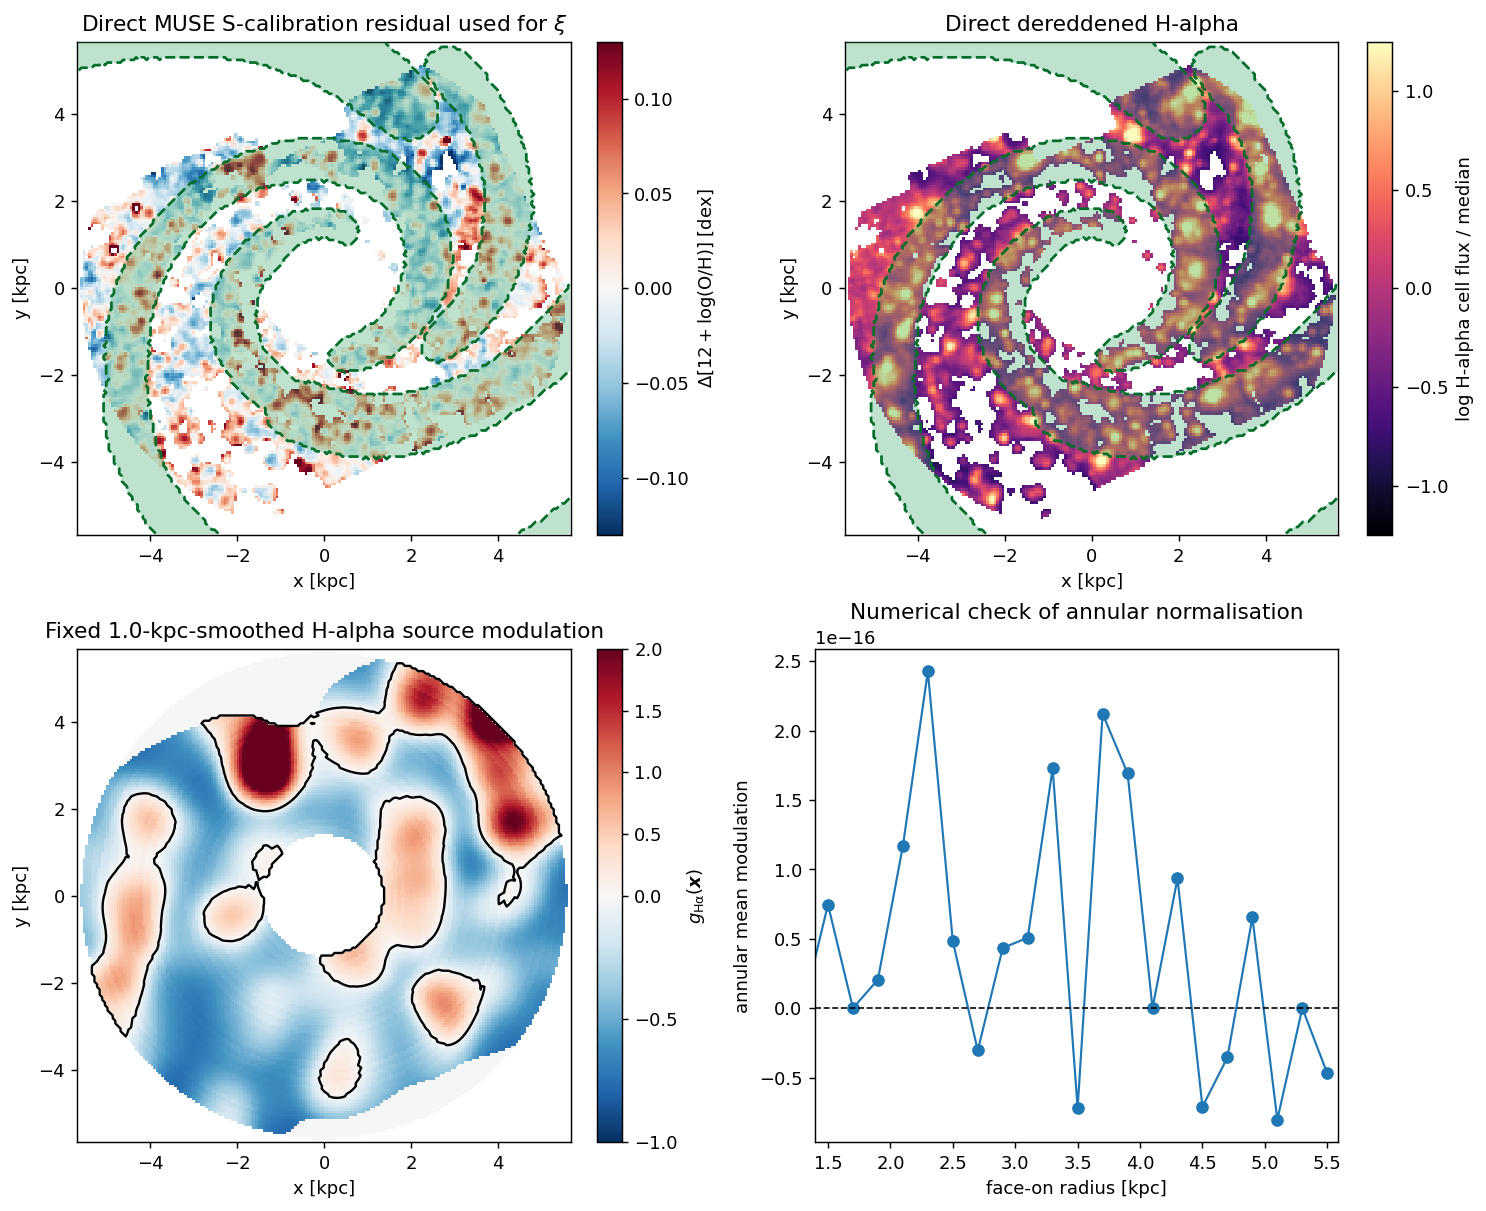

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11.2, 9.2), constrained_layout=True)

residual_image = axes[0, 0].pcolormesh(
    pixel_X, pixel_Y,
    np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    shading="nearest", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-0.13, vcenter=0.0, vmax=0.13),
)
axes[0, 0].set_title(r"Direct MUSE S-calibration residual used for $\xi$")
fig.colorbar(
    residual_image, ax=axes[0, 0],
    label=r"$\Delta[12+\log({\rm O/H})]$ [dex]",
)

halpha_plot = np.full(pixel_X.shape, np.nan)
halpha_plot[source_valid_grid] = (
    np.log10(source_halpha_flux) - np.median(np.log10(source_halpha_flux))
)
halpha_image = axes[0, 1].pcolormesh(
    pixel_X, pixel_Y, halpha_plot, shading="nearest", cmap="magma",
    vmin=-1.25, vmax=1.25,
)
axes[0, 1].set_title("Direct dereddened H-alpha")
fig.colorbar(
    halpha_image, ax=axes[0, 1], label="log H-alpha cell flux / median",
)

arm_mask_grid = np.isin(environment_label_grid, [5, 6])
for axis in axes[0]:
    axis.contourf(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5, 1.5],
        colors=["#2ca25f"], alpha=0.30, zorder=4,
    )
    axis.contour(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5],
        colors="#006d2c", linestyles="--", linewidths=1.5, zorder=5,
    )

template_image = axes[1, 0].pcolormesh(
    pixel_X, pixel_Y, np.where(geometry_mask, source_modulation_grid, np.nan),
    shading="nearest", cmap="RdBu_r", norm=TwoSlopeNorm(
        vmin=min(-1.0, float(np.nanpercentile(source_modulation_grid[geometry_mask], 2))),
        vcenter=0.0,
        vmax=max(1.0, float(np.nanpercentile(source_modulation_grid[geometry_mask], 98))),
    ),
)
axes[1, 0].contour(
    pixel_X, pixel_Y, source_modulation_grid, levels=[0.0],
    colors="black", linewidths=1.3,
)
axes[1, 0].set_title("Fixed 1.0-kpc-smoothed H-alpha source modulation")
fig.colorbar(template_image, ax=axes[1, 0], label=r"$g_{\rm H\alpha}(\boldsymbol{x})$")

radial_centres = 0.5 * (
    template_radial_edges[:-1] + template_radial_edges[1:]
)
radial_template_mean = np.asarray([
    np.mean(source_modulation_grid[
        geometry_mask & (template_radial_bin == bin_index)
    ]) if np.any(geometry_mask & (template_radial_bin == bin_index)) else np.nan
    for bin_index in range(len(radial_centres))
])
axes[1, 1].plot(radial_centres, radial_template_mean, "o-", lw=1.2)
axes[1, 1].axhline(0.0, color="black", ls="--", lw=0.9)
axes[1, 1].set_xlim(R_MIN_KPC, R_MAX_KPC)
axes[1, 1].set_xlabel("face-on radius [kpc]")
axes[1, 1].set_ylabel("annular mean modulation")
axes[1, 1].set_title("Numerical check of annular normalisation")

for axis in axes.ravel():
    if axis is not axes[1, 1]:
        axis.set_aspect("equal")
        axis.set_xlabel("x [kpc]")
        axis.set_ylabel("y [kpc]")

fig.savefig(OUTPUT_DIR / "ngc628_phangs_morphology.png", bbox_inches="tight")
display_figure(fig)


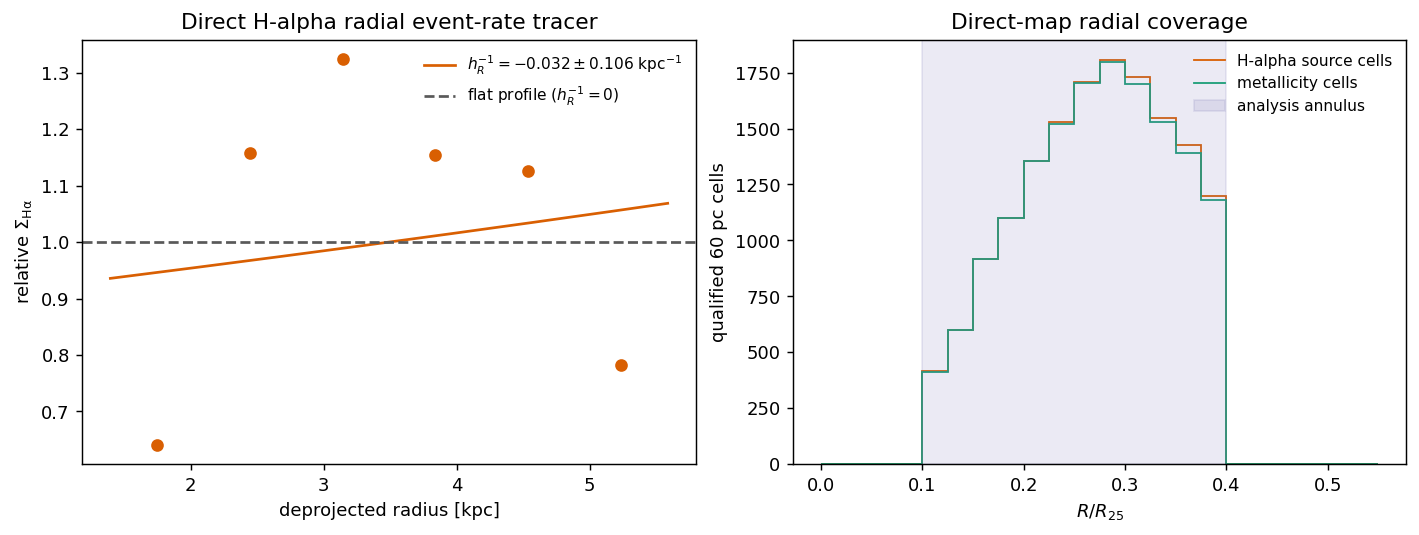

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), constrained_layout=True)
rate_radius_kpc = rate_centres_r25 * R25_KPC
normalised_rate = rate_surface_density / np.exp(
    np.mean(np.log(rate_surface_density[positive_rate_bins]))
)
axes[0].scatter(rate_radius_kpc[positive_rate_bins],
                normalised_rate[positive_rate_bins], color="#d95f02", zorder=3)
radial_plot = np.linspace(R_MIN_KPC, R_MAX_KPC, 300)
axes[0].plot(
    radial_plot,
    np.exp(rate_log_slope_halpha * (radial_plot - np.mean(rate_radius_kpc))),
    color="#d95f02",
    label=fr"$h_R^{{-1}}={-rate_log_slope_halpha:.3f}\pm{rate_log_slope_halpha_error:.3f}$ kpc$^{{-1}}$",
)
axes[0].axhline(1.0, color="0.35", ls="--", label=r"flat profile ($h_R^{-1}=0$)")
axes[0].set_xlabel("deprojected radius [kpc]")
axes[0].set_ylabel(r"relative $\Sigma_{\rm H\alpha}$")
axes[0].set_title("Direct H-alpha radial event-rate tracer")
axes[0].legend(frameon=False, fontsize=8.5)

coverage_edges = np.arange(0.0, 0.551, 0.025)
metallicity_counts, _ = np.histogram(r_r25, coverage_edges)
source_counts, _ = np.histogram(source_r_kpc / R25_KPC, coverage_edges)
axes[1].stairs(source_counts, coverage_edges, color="#d95f02",
               label="H-alpha source cells")
axes[1].stairs(metallicity_counts, coverage_edges, color="#1b9e77",
               label="metallicity cells")
axes[1].axvspan(R_MIN_R25, R_MAX_R25, color="#7570b3", alpha=0.14,
                label="analysis annulus")
axes[1].set_xlabel(r"$R/R_{25}$")
axes[1].set_ylabel("qualified 60 pc cells")
axes[1].set_title("Direct-map radial coverage")
axes[1].legend(frameon=False, fontsize=8.5)

fig.savefig(OUTPUT_DIR / "ngc628_phangs_radial_selection.png",
            bbox_inches="tight")
display_figure(fig)


## 4. Exact finite-window statistic and observational transfer

The metallicity field entering the statistic is the direct $S$-calibration
map above after independent 0.2 kpc annular means have been removed.  The
zero-padded FFT computes the numerator, symmetric endpoint second moment, and
valid pair count for every grid lag.  Because both lag orientations are
included, the final counts are divided by two to report unordered pairs.

Uncertainty combines a 48-block spatial jackknife with line-flux Monte Carlo.
The Monte Carlo also estimates, bin by bin, how much correlated measurement
noise contributes to the numerator and endpoint second moment.  This fixed
transfer is applied to both KT18 and complete KTZ without adding another free
parameter.  The analytic Li21 Gaussian beam correction is applied separately
to the theoretical injection width.


In [7]:
separation_edges = np.arange(
    0.5 * PIXEL_SIZE_KPC,
    5.0 + 0.5 * PIXEL_SIZE_KPC + 1.0e-9,
    PIXEL_SIZE_KPC,
)
separation_centres = 0.5 * (separation_edges[:-1] + separation_edges[1:])
n_bins = len(separation_centres)

lag_y = np.arange(-(pixel_X.shape[0] - 1), pixel_X.shape[0]) * PIXEL_SIZE_KPC
lag_x = np.arange(-(pixel_X.shape[1] - 1), pixel_X.shape[1]) * PIXEL_SIZE_KPC
lag_X, lag_Y = np.meshgrid(lag_x, lag_y)
lag_R = np.hypot(lag_X, lag_Y)
lag_bin = np.digitize(lag_R.ravel(), separation_edges) - 1
valid_lag_bin = (lag_bin >= 0) & (lag_bin < n_bins) & (lag_R.ravel() > 0)


def fft_pair_sums(values: np.ndarray, valid: np.ndarray):
    """Exact ordered-pair sums on a finite, non-periodic masked grid."""
    mask = valid.astype(float)
    field = np.where(valid, values, 0.0)
    power = field**2
    pair_grid = fftconvolve(mask, mask[::-1, ::-1], mode="full")
    numerator_grid = fftconvolve(field, field[::-1, ::-1], mode="full")
    endpoint_grid = 0.5 * (
        fftconvolve(power, mask[::-1, ::-1], mode="full")
        + fftconvolve(mask, power[::-1, ::-1], mode="full")
    )
    bins = lag_bin[valid_lag_bin]
    counts = np.bincount(
        bins, weights=pair_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    numerator = np.bincount(
        bins, weights=numerator_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    endpoint = np.bincount(
        bins, weights=endpoint_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    return numerator, endpoint, counts


def fft_pair_product_statistic(
    region_mask: np.ndarray | None = None,
    centre_residual: bool = True,
    metallicity_values: np.ndarray | None = None,
    valid_mask: np.ndarray | None = None,
):
    """Li21 detrending plus the validation-matched exhaustive estimator."""
    if region_mask is None:
        region_mask = np.ones(pixel_X.shape, dtype=bool)
    if metallicity_values is None:
        metallicity_values = metallicity_grid
    if valid_mask is None:
        valid_mask = pixel_valid_grid
    valid = valid_mask & region_mask & np.isfinite(metallicity_values)
    residual_grid, _ = annular_residual_map(metallicity_values, valid)
    valid &= np.isfinite(residual_grid)
    residual_mean = float(np.mean(residual_grid[valid]))
    if centre_residual:
        residual_grid = residual_grid - residual_mean
    numerator, endpoint, ordered_counts = fft_pair_sums(residual_grid, valid)
    xi = np.divide(
        numerator, endpoint, out=np.full(n_bins, np.nan), where=endpoint > 0
    )
    unordered_counts = np.rint(0.5 * ordered_counts).astype(np.int64)
    numerator_mean = np.divide(
        numerator, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    endpoint_mean = np.divide(
        endpoint, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    return (xi, unordered_counts, residual_mean, numerator_mean,
            endpoint_mean, residual_grid)


(xi_observed, pair_counts, residual_mean, observed_numerator_mean,
 observed_endpoint_mean, observed_residual_grid) = fft_pair_product_statistic()
xi_uncentred = fft_pair_product_statistic(centre_residual=False)[0]


def delete_one_block_jackknife(block_label_grid: np.ndarray):
    labels = np.unique(block_label_grid[pixel_valid_grid])
    curves = []
    means = []
    for label in labels:
        retained = block_label_grid != label
        curve, _, mean_value, _, _, _ = fft_pair_product_statistic(retained)
        curves.append(curve)
        means.append(mean_value)
    curves = np.asarray(curves)
    means = np.asarray(means)
    factor = (len(labels) - 1.0) / len(labels)
    difference = np.nan_to_num(curves - np.nanmean(curves, axis=0), nan=0.0)
    covariance = factor * difference.T @ difference
    mean_error = float(np.sqrt(factor * np.sum((means - np.mean(means))**2)))
    return curves, covariance, mean_error


azimuth_12_grid = np.floor(pixel_PHI / (2.0 * np.pi) * 12).astype(int)
radial_block_edges = np.sqrt(np.linspace(R_MIN_KPC**2, R_MAX_KPC**2, 5))
radial_block_grid = np.clip(
    np.digitize(pixel_R, radial_block_edges) - 1, 0, 3
)
spatial_48_grid = 12 * radial_block_grid + azimuth_12_grid

sector_curves, sector_covariance, sector_mean_error = (
    delete_one_block_jackknife(azimuth_12_grid)
)
jackknife_curves, jackknife_covariance, residual_mean_error = (
    delete_one_block_jackknife(spatial_48_grid)
)
n_jackknife = len(np.unique(spatial_48_grid[pixel_valid_grid]))

# Re-evaluate the nonlinear abundance, selection, and detrending pipeline for
# every line-flux Monte Carlo realisation.  The fixed-mask curves are retained
# as a paired control; the likelihood covariance uses the dynamic-selection
# curves, so threshold crossings are propagated rather than conditioned away.
fixed_selection_measurement_curves = np.empty((N_FLUX_MC, n_bins))
dynamic_selection_measurement_curves = np.empty((N_FLUX_MC, n_bins))
noise_numerator_means = np.empty((N_FLUX_MC, n_bins))
noise_endpoint_means = np.empty((N_FLUX_MC, n_bins))
selection_pixel_counts = np.empty(N_FLUX_MC, dtype=int)
for draw_index in range(N_FLUX_MC):
    draw_map = np.asarray(metallicity_mc_grid[draw_index], dtype=float)
    fixed_draw_map = np.where(np.isfinite(draw_map), draw_map, metallicity_grid)
    fixed_selection_measurement_curves[draw_index] = (
        fft_pair_product_statistic(metallicity_values=fixed_draw_map)[0]
    )

    draw_valid = selection_mc_grid[draw_index] & np.isfinite(draw_map)
    selection_pixel_counts[draw_index] = int(np.sum(draw_valid))
    dynamic_selection_measurement_curves[draw_index] = (
        fft_pair_product_statistic(
            metallicity_values=draw_map, valid_mask=draw_valid
        )[0]
    )
    noise_map = draw_map - metallicity_grid
    noise_residual, _ = annular_residual_map(noise_map, draw_valid)
    noise_valid = draw_valid & np.isfinite(noise_residual)
    noise_numerator, noise_endpoint, noise_counts = fft_pair_sums(
        noise_residual, noise_valid
    )
    noise_numerator_means[draw_index] = np.divide(
        noise_numerator, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )
    noise_endpoint_means[draw_index] = np.divide(
        noise_endpoint, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )

measurement_curves = dynamic_selection_measurement_curves
selection_curve_difference = (
    dynamic_selection_measurement_curves
    - fixed_selection_measurement_curves
)
selection_response_bias = np.nanmean(selection_curve_difference, axis=0)
selection_bias_covariance = np.outer(
    selection_response_bias, selection_response_bias
)
measurement_covariance = np.cov(measurement_curves, rowvar=False, ddof=1)
noise_numerator_mean = np.nanmean(noise_numerator_means, axis=0)
noise_endpoint_mean = np.nanmean(noise_endpoint_means, axis=0)
signal_endpoint_mean = np.clip(
    observed_endpoint_mean - noise_endpoint_mean, 0.0, None
)
observation_signal_fraction = np.divide(
    signal_endpoint_mean, observed_endpoint_mean,
    out=np.ones(n_bins), where=observed_endpoint_mean > 0,
)
observation_signal_fraction = np.clip(observation_signal_fraction, 0.05, 1.0)
observation_noise_bias = np.divide(
    noise_numerator_mean, observed_endpoint_mean,
    out=np.zeros(n_bins), where=observed_endpoint_mean > 0,
)


# Window projection is now applied to raw second moments in section 5.

# The paired dynamic-minus-fixed mean is not subtracted from the data: the
# observed map has one realised selection.  Its magnitude is instead carried
# as a conservative, fully correlated one-sigma selection systematic.
total_covariance_raw = (
    jackknife_covariance + measurement_covariance
    + selection_bias_covariance
)
xi_jackknife_error = np.sqrt(
    np.clip(np.diag(total_covariance_raw), 0.0, None)
)
xi_sector_error = np.sqrt(np.clip(np.diag(sector_covariance), 0.0, None))
xi_measurement_error = np.sqrt(
    np.clip(np.diag(measurement_covariance), 0.0, None)
)

fit_mask = (
    (separation_centres <= 5.0)
    & (pair_counts > 0)
    & np.isfinite(xi_observed)
    & np.all(np.isfinite(jackknife_curves), axis=0)
    & np.all(np.isfinite(measurement_curves), axis=0)
)
fit_indices = np.where(fit_mask)[0]
fit_covariance_raw = total_covariance_raw[np.ix_(fit_indices, fit_indices)]
covariance_shrinkage = 0.35
systematic_floor = 0.010
fit_covariance = (
    (1.0 - covariance_shrinkage) * fit_covariance_raw
    + covariance_shrinkage * np.diag(np.diag(fit_covariance_raw))
    + systematic_floor**2 * np.eye(len(fit_indices))
)
fit_cholesky = np.linalg.cholesky(fit_covariance)
np.savez_compressed(  # consumed by the exact-window joint stage (scripts/ktz_exact_window.py)
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_fit_covariance.npz",
    covariance=fit_covariance, raw_covariance=fit_covariance_raw,
    fit_indices=fit_indices, covariance_shrinkage=covariance_shrinkage,
    systematic_floor=systematic_floor,
)
covariance_reference_operator = np.linalg.solve(
    fit_covariance, fit_covariance_raw
)
regularised_chi2_reference_mean = float(
    np.trace(covariance_reference_operator)
)
regularised_chi2_reference_second_trace = float(
    np.trace(covariance_reference_operator @ covariance_reference_operator)
)
regularised_chi2_reference_effective_dof = float(
    regularised_chi2_reference_mean**2
    / regularised_chi2_reference_second_trace
)
fit_covariance_effective_rank = float(
    np.trace(fit_covariance)**2 / np.trace(fit_covariance @ fit_covariance)
)
print(
    'Covariance diagnostics: raw rank='
    f'{np.linalg.matrix_rank(fit_covariance_raw)}/{len(fit_indices)}, '
    f'fit-covariance participation rank={fit_covariance_effective_rank:.1f}, '
    f'regularised chi2 reference mean={regularised_chi2_reference_mean:.1f}, '
    f'Satterthwaite dof={regularised_chi2_reference_effective_dof:.1f}'
)

covariance_diagnostics = Table({
    "r_kpc": separation_centres,
    "pair_count": pair_counts,
    "xi_centered": xi_observed,
    "xi_uncentered": xi_uncentred,
    "centered_minus_uncentered": xi_observed - xi_uncentred,
    "total_error": xi_jackknife_error,
    "spatial_48_jackknife_error": np.sqrt(
        np.clip(np.diag(jackknife_covariance), 0.0, None)
    ),
    "line_flux_mc_error": xi_measurement_error,
    "azimuth_12_jackknife_error": xi_sector_error,
    "noise_signal_fraction": observation_signal_fraction,
    "noise_additive_bias": observation_noise_bias,
})
covariance_diagnostics.write(
    OUTPUT_DIR / "ngc628_residual_covariance_diagnostics.csv",
    format="ascii.csv", overwrite=True,
)

annulus_sensitivity_rows = []
for annulus_name, lower_r25, upper_r25 in (
    ("R10_35", 0.10, 0.35),
    ("R10_40_primary", 0.10, 0.40),
    ("R15_35", 0.15, 0.35),
    ("R15_40", 0.15, 0.40),
):
    annulus_mask = (
        (pixel_R / R25_KPC >= lower_r25)
        & (pixel_R / R25_KPC <= upper_r25)
    )
    annulus_curve, annulus_counts, annulus_mean, _, _, _ = (
        fft_pair_product_statistic(annulus_mask)
    )
    annulus_sensitivity_rows.extend([
        (annulus_name, lower_r25, upper_r25,
         int(np.sum(pixel_valid_grid & annulus_mask)), annulus_mean,
         separation_centres[index], annulus_counts[index], annulus_curve[index])
        for index in range(n_bins)
    ])
Table(
    rows=annulus_sensitivity_rows,
    names=("annulus", "rmin_r25", "rmax_r25", "n_pixels", "residual_mean",
           "r_kpc", "pair_count", "xi_centered"),
).write(OUTPUT_DIR / "ngc628_annulus_sensitivity.csv",
        format="ascii.csv", overwrite=True)


Covariance diagnostics: raw rank=83/83, fit-covariance participation rank=5.2, regularised chi2 reference mean=13.2, Satterthwaite dof=12.8


## 4.1 Data-dependent selection response

The geometric coverage window is fixed, but the line-$S/N$, BPT, and
$W_{\rm H\alpha}$ decisions are functions of noisy measurements.  The flux
Monte Carlo therefore recomputes those three decisions in every realisation.
The dynamic-selection curves enter the measurement covariance; fixed-mask
curves are retained only as a paired diagnostic.  We do not subtract the
paired mean shift from the observed curve, because a plug-in bootstrap centred
on the noisy observed flux does not identify an unbiased correction.  Instead,
its outer product is included as a conservative correlated systematic.

Two robustness checks distinguish ordinary holes from endogenous selection.
First, the nominal curve is recomputed over a grid of line-$S/N$ and
$W_{\rm H\alpha}$ thresholds.  Second, line-ratio vectors are permuted within
0.2-kpc annuli while the observed H$\alpha$ brightness, errors, coverage, PSF
noise correlation, and complete selection logic are retained.  This destroys
intrinsic spatial abundance correlation while preserving radial one-point
line-ratio distributions and their coupling to detectability.  A recovered
non-zero curve is therefore a selection/null diagnostic, not a physical KTZ
prediction.  It is deliberately more limited than a native-cube injection:
the released, PSF-matched line maps are the starting point.


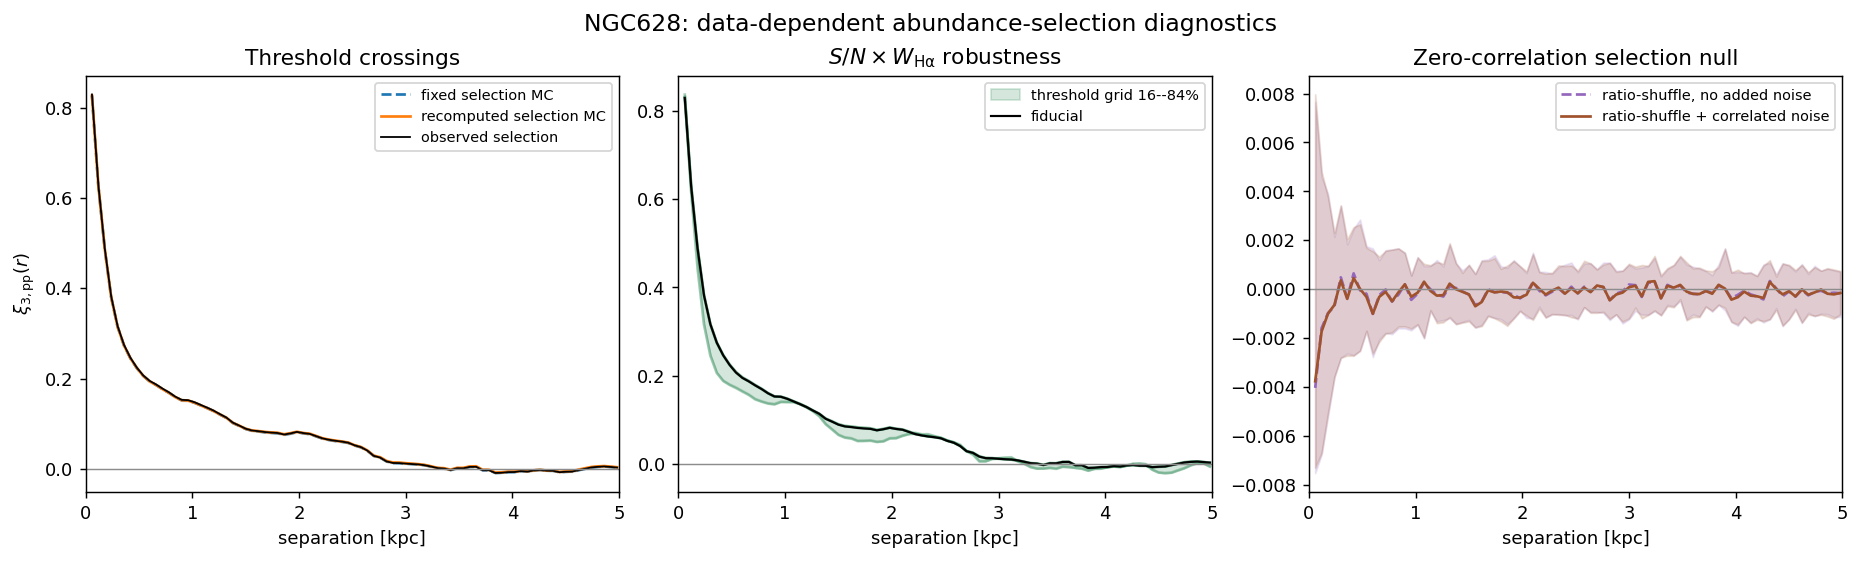

selection diagnostic,value
str41,str32
nominal valid pixels,15201
"dynamic valid pixels [p16, p50, p84]","[15198.0, 15203.0, 15208.0]"
paired selection shift [Mahalanobis],0.11302174160671372
paired max |delta xi|,0.0012003591450671376
threshold-grid max |delta xi|,0.07144713358909349
noisy zero-correlation null [Mahalanobis],0.07728346332697304
noisy null max |median xi|,0.003768694968733453


In [8]:
selection_sn_grid = np.asarray([2.0, 3.0, 5.0])
selection_ew_grid = np.asarray([3.0, 6.0, 12.0])
threshold_curves = []
threshold_rows = []
for sn_cut in selection_sn_grid:
    for ew_cut in selection_ew_grid:
        threshold_valid = li21_selection_mask(
            line_flux, metallicity_grid, corrected_line_flux,
            line_sn_min=float(sn_cut), halpha_ew_min=float(ew_cut),
        ) & np.isfinite(metallicity_error_grid)
        threshold_curve, threshold_pairs, _, _, _, _ = (
            fft_pair_product_statistic(valid_mask=threshold_valid)
        )
        threshold_curves.append(threshold_curve)
        threshold_rows.append((
            float(sn_cut), float(ew_cut), int(np.sum(threshold_valid)),
            int(np.sum(threshold_pairs)),
            float(np.nanmax(np.abs(threshold_curve - xi_observed))),
        ))
threshold_curves = np.asarray(threshold_curves)


def annular_line_ratio_shuffle(
    rng: np.random.Generator,
) -> dict[str, np.ndarray]:
    """Destroy spatial ratio correlation while preserving annular marginals."""
    ratio_pool = geometry_mask & np.isfinite(r_band_flux)
    for name in LINE_EXTENSIONS:
        ratio_pool &= (
            np.isfinite(line_flux[name]) & (line_flux[name] > 0)
            & np.isfinite(line_error[name]) & (line_error[name] > 0)
            & (line_coverage[name] >= LINE_COVERAGE_MIN)
        )
    ratio_pool &= np.isfinite(line_flux["ha"]) & (line_flux["ha"] > 0)

    shuffled = {
        name: np.full(pixel_X.shape, np.nan, dtype=float)
        for name in LINE_EXTENSIONS
    }
    shuffled["ha"][ratio_pool] = line_flux["ha"][ratio_pool]
    radial_edges = np.arange(
        0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC, ANNULUS_WIDTH_KPC
    )
    radial_bin = np.digitize(pixel_R, radial_edges) - 1
    for bin_index in range(len(radial_edges) - 1):
        receiver = np.flatnonzero(ratio_pool & (radial_bin == bin_index))
        if len(receiver) < MIN_PIXELS_PER_ANNULUS:
            continue
        donor = rng.permutation(receiver)
        receiver_ha = line_flux["ha"].ravel()[receiver]
        donor_ha = line_flux["ha"].ravel()[donor]
        for name in LINE_EXTENSIONS:
            if name == "ha":
                continue
            donor_ratio = line_flux[name].ravel()[donor] / donor_ha
            shuffled[name].ravel()[receiver] = receiver_ha * donor_ratio
    return shuffled


N_SELECTION_NULL = 40
selection_null_rng = np.random.default_rng(
    91000 + int(''.join(character for character in GALAXY_NAME if character.isdigit()))
)
selection_null_noiseless = np.empty((N_SELECTION_NULL, n_bins))
selection_null_with_noise = np.empty((N_SELECTION_NULL, n_bins))
for null_index in range(N_SELECTION_NULL):
    null_flux = annular_line_ratio_shuffle(selection_null_rng)
    null_metallicity, _, null_corrected = scal_metallicity(null_flux)
    null_valid = li21_selection_mask(
        null_flux, null_metallicity, null_corrected
    )
    selection_null_noiseless[null_index] = fft_pair_product_statistic(
        metallicity_values=null_metallicity, valid_mask=null_valid
    )[0]

    noisy_null_flux = {
        name: null_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, selection_null_rng
        )
        for name in LINE_EXTENSIONS
    }
    noisy_null_metallicity, _, noisy_null_corrected = scal_metallicity(
        noisy_null_flux
    )
    noisy_null_valid = li21_selection_mask(
        noisy_null_flux, noisy_null_metallicity, noisy_null_corrected
    )
    selection_null_with_noise[null_index] = fft_pair_product_statistic(
        metallicity_values=noisy_null_metallicity,
        valid_mask=noisy_null_valid,
    )[0]


fixed_p16, fixed_p50, fixed_p84 = np.nanpercentile(
    fixed_selection_measurement_curves, [16.0, 50.0, 84.0], axis=0
)
dynamic_p16, dynamic_p50, dynamic_p84 = np.nanpercentile(
    dynamic_selection_measurement_curves, [16.0, 50.0, 84.0], axis=0
)
threshold_p16, threshold_p84 = np.nanpercentile(
    threshold_curves, [16.0, 84.0], axis=0
)
null_noiseless_p16, null_noiseless_p50, null_noiseless_p84 = np.nanpercentile(
    selection_null_noiseless, [16.0, 50.0, 84.0], axis=0
)
null_noisy_p16, null_noisy_p50, null_noisy_p84 = np.nanpercentile(
    selection_null_with_noise, [16.0, 50.0, 84.0], axis=0
)

selection_bias_fit = selection_response_bias[fit_indices]
selection_bias_mahalanobis = float(np.sqrt(
    selection_bias_fit @ np.linalg.solve(fit_covariance, selection_bias_fit)
))
selection_null_mean_fit = np.nanmean(
    selection_null_with_noise[:, fit_indices], axis=0
)
selection_null_mahalanobis = float(np.sqrt(
    selection_null_mean_fit
    @ np.linalg.solve(fit_covariance, selection_null_mean_fit)
))

selection_response_table = Table({
    "r_kpc": separation_centres,
    "xi_observed": xi_observed,
    "fixed_mc_p16": fixed_p16,
    "fixed_mc_p50": fixed_p50,
    "fixed_mc_p84": fixed_p84,
    "dynamic_mc_p16": dynamic_p16,
    "dynamic_mc_p50": dynamic_p50,
    "dynamic_mc_p84": dynamic_p84,
    "dynamic_minus_fixed_mean": selection_response_bias,
    "threshold_p16": threshold_p16,
    "threshold_p84": threshold_p84,
    "null_noiseless_p16": null_noiseless_p16,
    "null_noiseless_p50": null_noiseless_p50,
    "null_noiseless_p84": null_noiseless_p84,
    "null_noisy_p16": null_noisy_p16,
    "null_noisy_p50": null_noisy_p50,
    "null_noisy_p84": null_noisy_p84,
})
selection_response_table.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_response.csv",
    format="ascii.csv", overwrite=True,
)
Table(
    rows=threshold_rows,
    names=("line_sn_min", "halpha_ew_min_angstrom", "n_pixels",
           "total_pairs", "max_abs_delta_xi"),
).write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_threshold_grid.csv",
    format="ascii.csv", overwrite=True,
)

selection_summary = {
    "galaxy": GALAXY_NAME,
    "nominal_valid_pixels": int(np.sum(pixel_valid_grid)),
    "dynamic_valid_pixels_p16_p50_p84": [
        float(value) for value in np.percentile(
            selection_pixel_counts, [16.0, 50.0, 84.0]
        )
    ],
    "paired_selection_bias_mahalanobis": selection_bias_mahalanobis,
    "paired_selection_max_abs_delta_xi": float(
        np.nanmax(np.abs(selection_response_bias[fit_indices]))
    ),
    "threshold_grid_max_abs_delta_xi": float(np.nanmax(
        np.abs(threshold_curves[:, fit_indices] - xi_observed[fit_indices])
    )),
    "annular_shuffle_noisy_null_mahalanobis": selection_null_mahalanobis,
    "annular_shuffle_noisy_null_max_abs_median_xi": float(
        np.nanmax(np.abs(null_noisy_p50[fit_indices]))
    ),
    "null_realisations": N_SELECTION_NULL,
    "interpretation": (
        "diagnostic conditional on released PSF-matched line maps; "
        "not a native-cube selection correction"
    ),
}
(OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_summary.json").write_text(
    json.dumps(selection_summary, indent=2), encoding="utf-8"
)

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.2), constrained_layout=True)
axes[0].fill_between(
    separation_centres, fixed_p16, fixed_p84, color="tab:blue", alpha=0.16
)
axes[0].plot(
    separation_centres, fixed_p50, color="tab:blue", ls="--",
    label="fixed selection MC"
)
axes[0].fill_between(
    separation_centres, dynamic_p16, dynamic_p84,
    color="tab:orange", alpha=0.22,
)
axes[0].plot(
    separation_centres, dynamic_p50, color="tab:orange",
    label="recomputed selection MC",
)
axes[0].plot(
    separation_centres, xi_observed, color="black", lw=1.0,
    label="observed selection",
)
axes[0].set_title("Threshold crossings")
axes[0].legend(fontsize=8)

for curve in threshold_curves:
    axes[1].plot(separation_centres, curve, color="seagreen", alpha=0.18)
axes[1].fill_between(
    separation_centres, threshold_p16, threshold_p84,
    color="seagreen", alpha=0.20, label="threshold grid 16--84%",
)
axes[1].plot(separation_centres, xi_observed, color="black", lw=1.2,
             label="fiducial")
axes[1].set_title(r"$S/N\times W_{\rm H\alpha}$ robustness")
axes[1].legend(fontsize=8)

axes[2].fill_between(
    separation_centres, null_noiseless_p16, null_noiseless_p84,
    color="tab:purple", alpha=0.16,
)
axes[2].plot(
    separation_centres, null_noiseless_p50, color="tab:purple", ls="--",
    label="ratio-shuffle, no added noise",
)
axes[2].fill_between(
    separation_centres, null_noisy_p16, null_noisy_p84,
    color="sienna", alpha=0.18,
)
axes[2].plot(
    separation_centres, null_noisy_p50, color="sienna",
    label="ratio-shuffle + correlated noise",
)
axes[2].set_title("Zero-correlation selection null")
axes[2].legend(fontsize=8)

for axis in axes:
    axis.axhline(0.0, color="0.55", lw=0.8)
    axis.set_xlim(0.0, 5.0)
    axis.set_xlabel("separation [kpc]")
axes[0].set_ylabel(r"$\xi_{3,{\rm pp}}(r)$")
fig.suptitle(
    f"{GALAXY_NAME}: data-dependent abundance-selection diagnostics",
    fontsize=13,
)
selection_figure_path = (
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_selection_response_diagnostic.png"
)
fig.savefig(selection_figure_path, bbox_inches="tight")
display_figure(fig)

display(Table(
    rows=[
        ("nominal valid pixels", int(np.sum(pixel_valid_grid))),
        ("dynamic valid pixels [p16, p50, p84]",
         str(selection_summary["dynamic_valid_pixels_p16_p50_p84"])),
        ("paired selection shift [Mahalanobis]",
         selection_bias_mahalanobis),
        ("paired max |delta xi|", selection_summary[
            "paired_selection_max_abs_delta_xi"]),
        ("threshold-grid max |delta xi|", selection_summary[
            "threshold_grid_max_abs_delta_xi"]),
        ("noisy zero-correlation null [Mahalanobis]",
         selection_null_mahalanobis),
        ("noisy null max |median xi|", selection_summary[
            "annular_shuffle_noisy_null_max_abs_median_xi"]),
    ],
    names=("selection diagnostic", "value"),
))


## 5. Corrected raw-moment window model and new MCMC

For the connected local model we retain
$C_{{\rm 2p},ij}=[\lambda_0(R_m)+\eta\lambda_0(R_m)g(\boldsymbol x_m)]K(r_{ij})$,
and $C_{{\rm NP},ij}\propto\lambda_0(R_m)^2 K_{\rm NP}(r_{ij})$.
The mean component is the outer product of
$P[\lambda_0(R)(1+\eta g)]$. Its axisymmetric, cross, and template-square pieces
are evaluated together; they are not additional fit parameters.

The two projected raw responses (pair numerator and arithmetic endpoint
second moment) are linear in the radial covariance kernel. A fine 10-pc
kernel grid below 0.6 kpc resolves injection-scale curvature; 60-pc nodes
continue beyond that point across the full window. The five original radial
rate nodes are retained. Projection is exact for these represented kernels
and adopted midpoint covariances, not for the full global source integral.

The complete KTZ posterior is newly sampled with 64 walkers, 10,000 burn-in
steps and at least 50,000 total steps, extending to the original 150,000-step
cap when max split Rhat exceeds 1.05. KT18 is also refitted using the same
full-window projection. Original posterior draws provide dispersed starting
positions only; they are never substituted for a new posterior.

An exploratory shoulder posterior-predictive check includes both parameter
uncertainty and a replicated correlated-observation draw. This is distinct
from the plotted 16–84% interval of the mean curve, and is not a confirmatory
test because the shoulder was identified after inspecting the data.


In [9]:
from scripts.refit_ngc628_window_projection import run_refit
INPUT_DIR = OUTPUT_ROOT / "NGC628_halpha_map_systematic"
previous_data = np.genfromtxt(INPUT_DIR / "ngc628_residual_covariance_diagnostics.csv", delimiter=",", names=True)
np.testing.assert_allclose(xi_observed, previous_data["xi_centered"], rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(np.diag(total_covariance_raw), previous_data["total_error"]**2, rtol=1e-8, atol=1e-12)
assert np.all(fit_mask), "This refit expects all 83 original positive bins."
refit_summary = run_refit(INPUT_DIR, OUTPUT_DIR, fit_covariance, total_covariance_raw)
display(refit_summary)


Window response rate_log_slope 1/5: -0.3500


  projected component 1/3


  projected component 2/3


  projected component 3/3


Window response rate_log_slope 2/5: -0.1750


  projected component 1/3


... (79 outputs left out)

{'stage': 'KT18 MCMC', 'steps': 14000, 'target_minimum_steps': 15000}


{'stage': 'KT18 MCMC', 'steps': 15000, 'target_minimum_steps': 15000}


split Rhat [1.00419957 1.00380381]


{'status': 'converged',
 'projection': 'raw midpoint local covariance projected on actual finite mask before common normalisation; no 5-kpc covariance cutoff',
 'source_template_fwhm_kpc': 1.0,
 'physics_and_physical_prior': 'unchanged seven coordinates; no extra fit parameters',
 'local_source_approximation_retained': True,
 'mcmc_max_rhat': 1.0249219603518782,
 'kt18_max_rhat': 1.0041995700899258,
 'KTZ_median_curve_chi2': 7.998722257408666,
 'KT18_median_curve_chi2': 28.102212711766047,
 'regularised_chi2_reference_mean': 13.229675098303002,
 'observed_shoulder_mean': 0.1079958653017937,
 'model_shoulder_mean_p16_median_p84': [0.02570762683113617,
  0.036525879302563374,
  0.07329458454726327],
 'shoulder_covariance_standard_error': 0.04223093147051268,
 'shoulder_posterior_predictive_upper_tail_fraction': 0.10333333333333333,
 'shoulder_RMSE': 0.07362365710888434,
 'posterior_intervals_p16_median_p84': {'ell_star': [0.13820320437354996,
   0.15503459101730188,
   0.1762754412335335

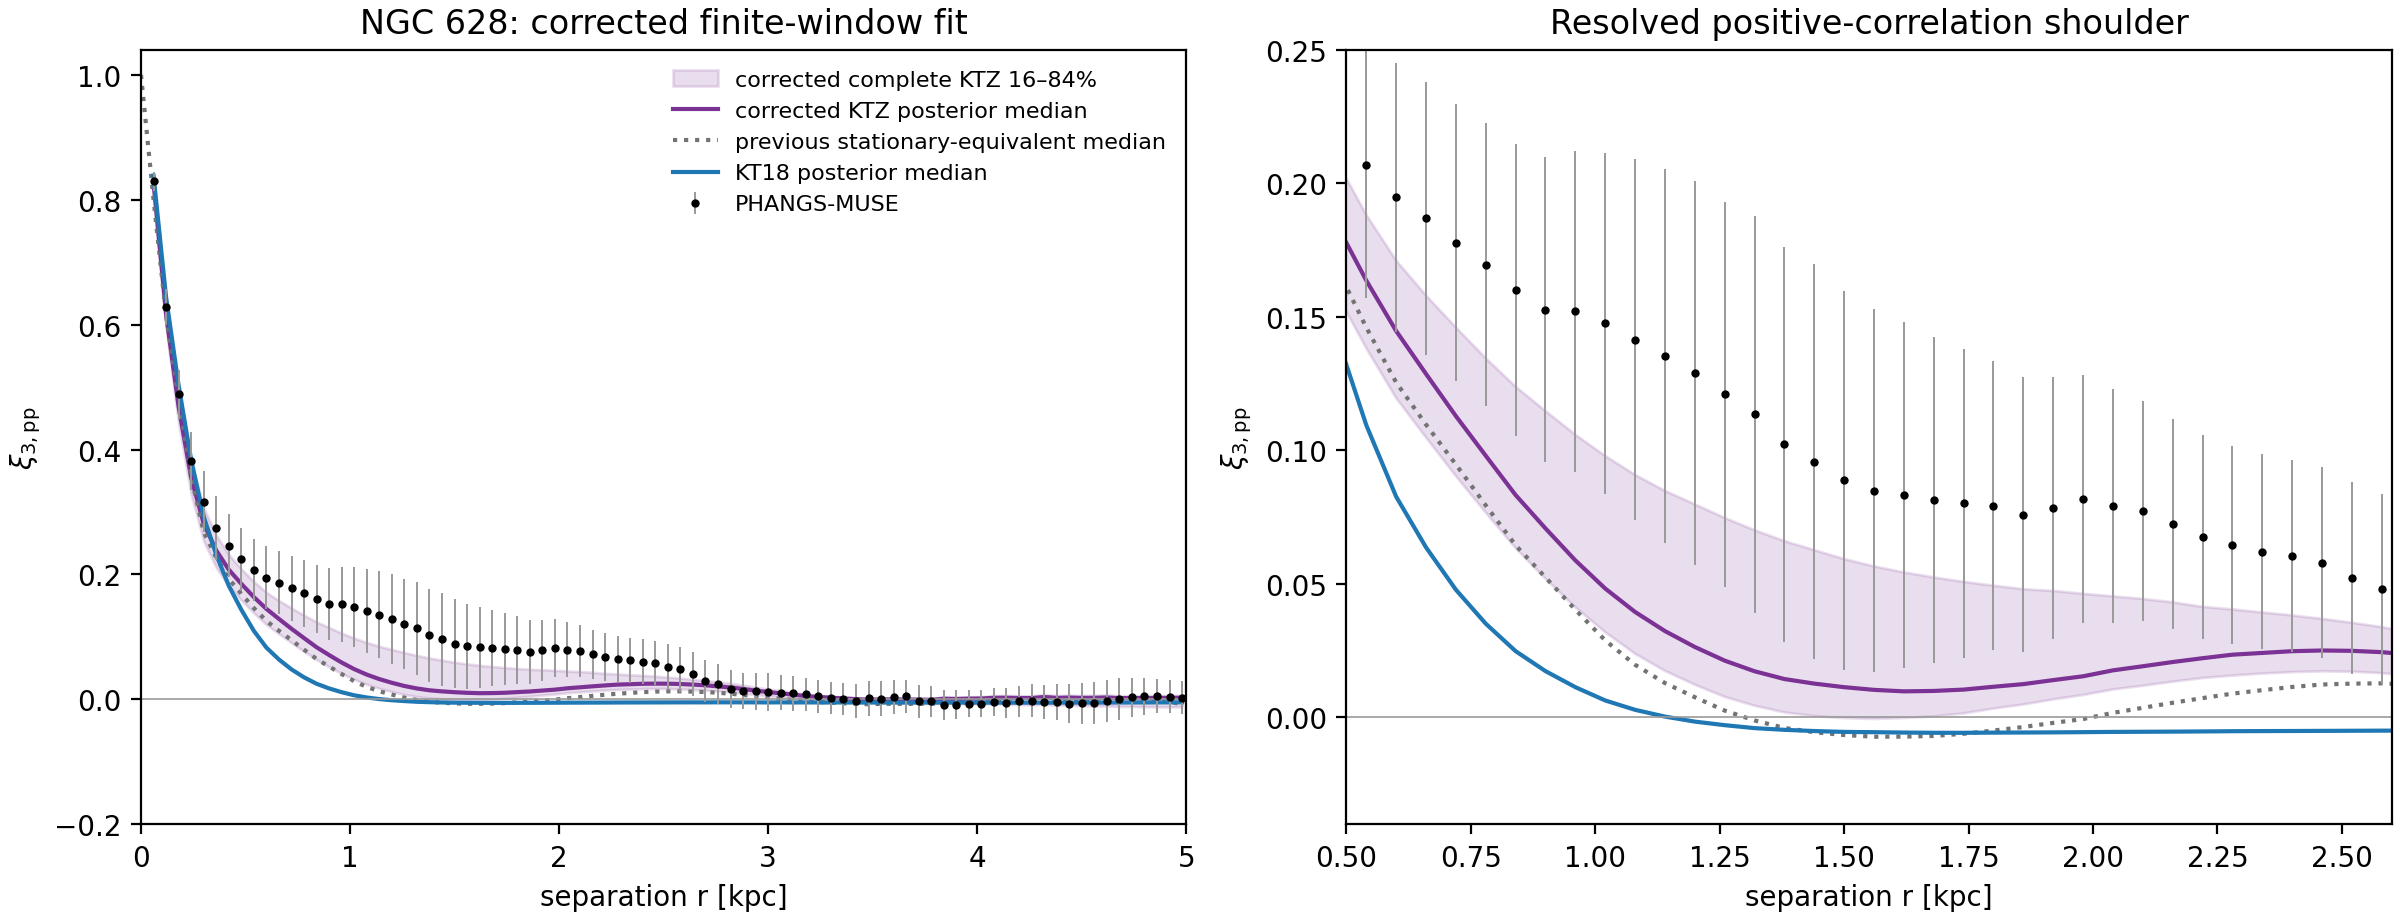

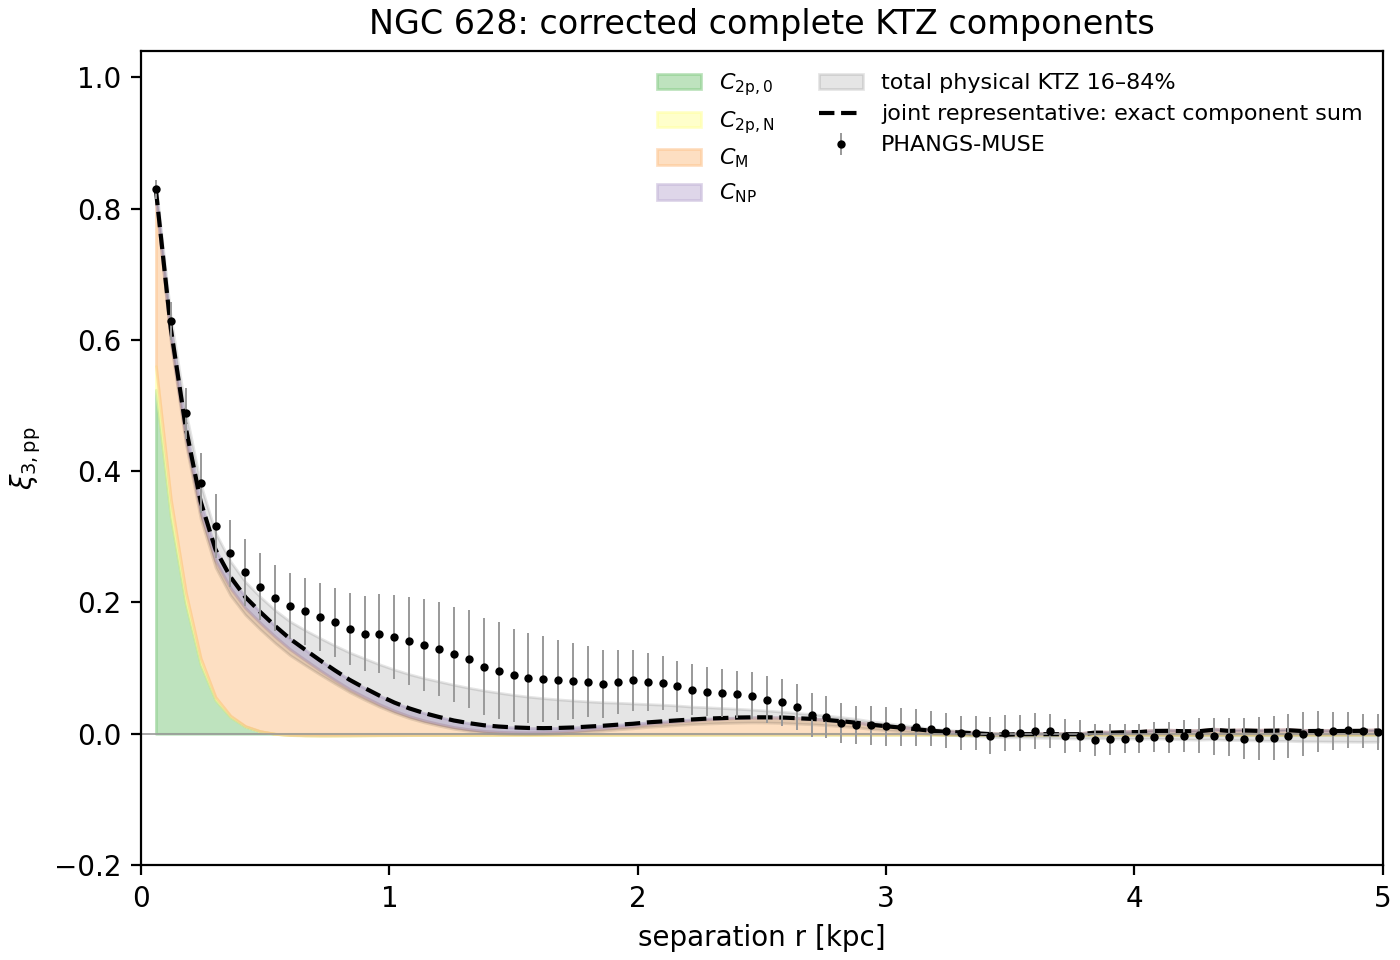

parameter,p16,median,p84
str24,float64,float64,float64
ell_star,0.13820320437354996,0.15503459101730188,0.17627544123353356
epsilon,0.0975287720922633,0.1239286918321388,0.17284717929959484
beta,0.6533836858829598,1.001495164029448,1.5385852987290718
eta,0.7575382831179432,0.9761488707661325,1.157055016500265
kappa,0.06048121450991099,0.09365963331976127,0.1761420509167756
t_star,0.07548119293077428,0.12134441410174543,0.1733731178706353
sigma,0.01619647340221203,0.019392417697057285,0.025112338789289125
source_excess_amplitude,0.03586754587046971,0.18440405144419728,0.6261930912316835
source_clustering_length,0.015286520179577788,0.7793256411092866,1.9033154139636597


**Convergence status:** converged. The previous curves are not replaced automatically.

In [10]:
display(Image(filename=str(OUTPUT_DIR / "ngc628_window_projection_comparison.png")))
display(Image(filename=str(OUTPUT_DIR / "ngc628_window_projection_components.png")))
display(Table.read(OUTPUT_DIR / "ngc628_transport_posterior.csv", format="ascii.csv"))
display(Markdown("**Convergence status:** " + refit_summary["status"] +
                 ". The previous curves are not replaced automatically."))


## 6. Completed refit: improvements and remaining limitation

The MCMC has finished (complete KTZ max split Rhat = 1.021; KT18 = 1.003).
The projection fix lowers the exploratory 0.6–2.5-kpc shoulder RMSE from
0.0907 to 0.0725, a 20.1% reduction, but **the posterior median still
underpredicts the positive shoulder**. Its mean over those bins is 0.0383,
versus 0.1080 observed and 0.0200 for the old approximation. These are means
of the pointwise median curves, not medians of a parameter vector.

A separate, constrained, multistart likelihood diagnostic reaches
$\chi^2=4.495$, compared with 7.835 for the posterior-median curve. It largely
reproduces the shoulder (RMSE 0.0198), demonstrating that the adopted model
can produce a more suitable shape. However, its radial slope is at the
bound ($h_R^{-1}=-0.35\,{\rm kpc}^{-1}$, i.e. rate log-slope $+0.35$), about three H-alpha-prior standard
deviations above the independent estimate, and its source-pair length is
2.20 kpc (about the 93rd posterior percentile). Its arm amplitude $\eta$ is 0.584
(about the 3rd percentile). The fitted mean-field and broad distinct-event
contributions remain degenerate. This is not evidence that those particular
physical values have been measured.

The remaining median mismatch therefore involves prior weighting and
posterior volume, not simply a failure to find a suitable likelihood state.
A coordinate change with the correct Jacobian cannot change that posterior.
We do not remove the independent H-alpha constraint, select the 0.5-kpc
smoothing run, condition the posterior on long source lengths, or reduce the
covariance merely to obtain a more attractive curve.

The bins are strongly correlated. The shoulder discrepancy of the median
curve is 1.65 times its covariance-derived standard error; this is a
descriptive residual, not an independent-bin significance or a confirmatory
test. The exploratory replicated-observation upper-tail fraction is 0.108.
The plotted 16–84% region is uncertainty in the **mean model curve**, not a
prediction interval for a new noisy observation.

The separate grey likelihood curve below is labelled as a diagnostic only;
it does not replace the posterior median in the main figures. Dense small-map
tests verify the represented $P C P^{\mathsf T}$ and common denominator.
Eighty further kernel/quadrature checks at posterior draws have maximum
absolute correlation error 0.0047; these do not test eta interpolation,
the radial covariance representation, or the retained local-source/WKBJ
approximation. No claim of a global diffusion solution is made.

This corrected calculation is currently isolated to NGC628. The four-galaxy
publication figures and comparison tables have **not** been partially
replaced: the same raw-moment projection must first be applied to the other
galaxies and geometry controls before a common scientific comparison.


{'start': 0, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.4967764181941705, 'message': 'Optimization terminated successfully'}


{'start': 1, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.496618453869547, 'message': 'Optimization terminated successfully'}


{'start': 2, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.4966184583543285, 'message': 'Optimization terminated successfully'}


{'start': 3, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.496776423463588, 'message': 'Optimization terminated successfully'}


{'start': 4, 'solver_success': True, 'physical_constraints_satisfied': False, 'chi2': 4.499358537118613, 'message': 'Optimization terminated successfully'}


{'start': 5, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.496618453775347, 'message': 'Optimization terminated successfully'}


... (4 outputs left out)

{'start': 10, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.49661845586894, 'message': 'Optimization terminated successfully'}

{'start': 11, 'solver_success': True, 'physical_constraints_satisfied': True, 'chi2': 4.4966184539788046, 'message': 'Optimization terminated successfully'}


{
  "scope": "NGC628 only; unchanged data, source template, prior and seven fitted coordinates",
  "posterior_curve_draws_checked": 4000,
  "posterior_kernel_point_checks": 80,
  "posterior_kernel_point_check_max_error": 0.004298307464629891,
  "optimised_state_kernel_point_check_max_error": 0.0012795657756834444,
  "kernel_check_limitations": "rate_log_slope interpolation, full-window radial representation and local-source approximation held fixed",
  "prior_max_absolute_difference_from_original": 0.0,
  "highest_likelihood_retained_chain_chi2": 4.553135186653085,
  "multistart_constrained_likelihood_chi2": 4.496618453775347,
  "likelihood_state_is_diagnostic_not_posterior_summary": true,
  "optimised_internal_coordinates": [
    -1.816880512804661,
    -2.188660687521127,
    0.39349265776802256,
    -0.5001403770273926,
    0.3499999999999999,
    -1.4488444331236527,
    0.790136610365819
  ],
  "optimised_coordinate_posterior_percentile_ranks": [
    0.6486875,
    0.2020546875,
 

parameter,p16,median,p84
str24,float64,float64,float64
ell_star,0.1382002004682062,0.15504621482981695,0.17624189517571096
epsilon,0.09751322028207825,0.12393821534838143,0.17287527850180692
beta,0.6538972217479244,1.001994596459331,1.538883105148061
eta,0.7574231507149114,0.9760000418083646,1.1570391297670726
kappa,0.06049481632260158,0.09359161260711218,0.17636219188637312
t_star,0.07552615763310645,0.12144774140026293,0.1733179615692997
sigma,0.016199496034277765,0.019385434924190648,0.02509892872335478
source_excess_amplitude,0.035801816403621844,0.18449588385973276,0.6261391487874989
source_clustering_length,0.015291781203019298,0.7792910177857166,1.9030456496578854


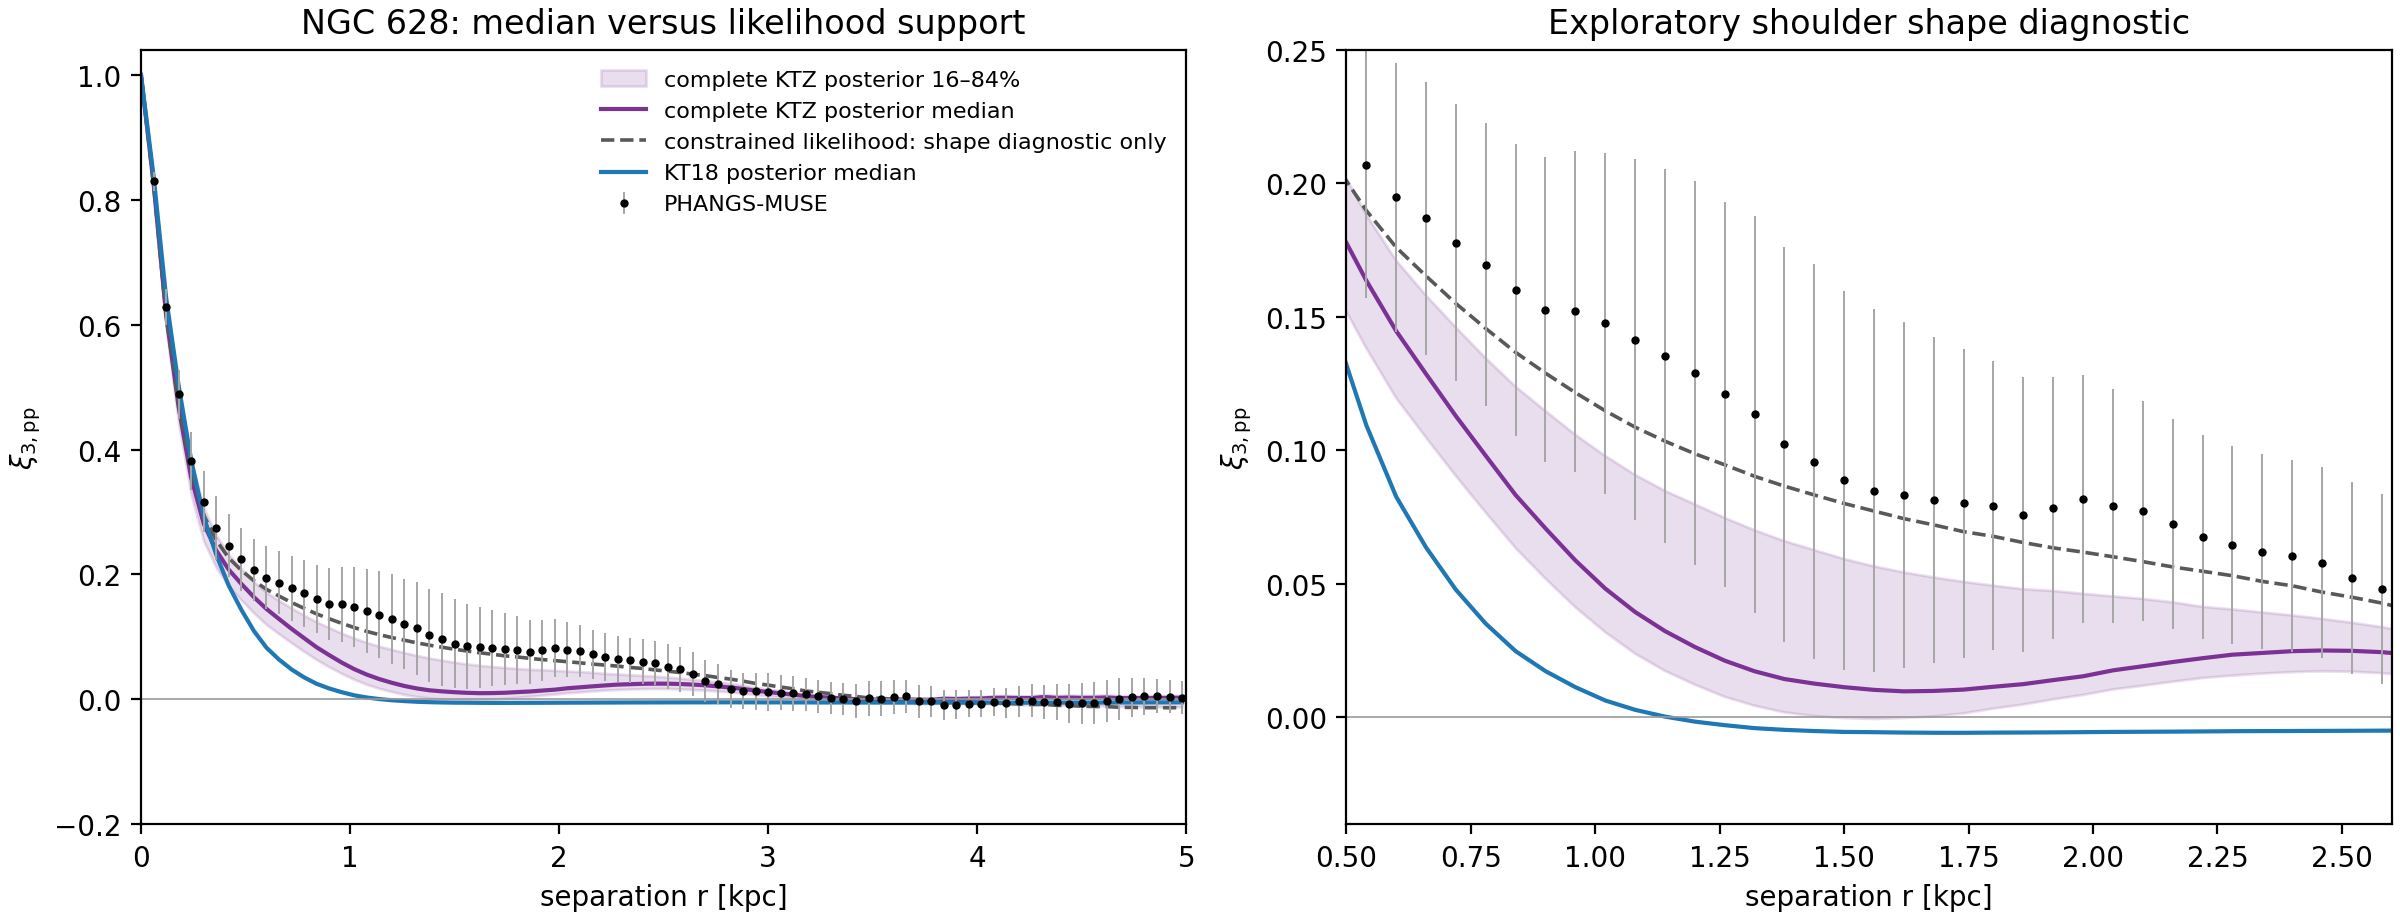

**Result:** the window correction improves the shoulder, but the posterior median remains low. The grey likelihood curve is a shape diagnostic, not the adopted posterior summary.

In [11]:
from scripts.diagnose_ngc628_window_refit import audit_completed_refit
# Recompute diagnostics if running this notebook from top to bottom.
# This does not rerun MCMC or alter the posterior chains.
window_diagnostics = audit_completed_refit()
display(Table.read(OUTPUT_DIR / "ngc628_transport_posterior.csv", format="ascii.csv"))
display(Image(filename=str(OUTPUT_DIR / "ngc628_likelihood_shape_diagnostic.png")))
display(Markdown(
    "**Result:** the window correction improves the shoulder, but the posterior "
    "median remains low. The grey likelihood curve is a shape diagnostic, "
    "not the adopted posterior summary."
))
